In [1]:

from google.colab import files

uploaded = files.upload()  # Select ML_Budget_Dataset_WorldBank_Filled(1).xlsx from your machine

ModuleNotFoundError: No module named 'google.colab'

In [ ]:

from google.colab import files

uploaded = files.upload()  # Select ML_Budget_Dataset_WorldBank_Filled(1).xlsx from your machine

Saving database_2026(1).xlsx to database_2026(1).xlsx


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load the completed dataset
file_path = "ML_Budget_Dataset_WorldBank_Completed.xlsx"
df = pd.read_excel(file_path, sheet_name="Completed_Dataset")

# 2. Define Input Features (X) - 18 core indicators
feature_cols = [
    'population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd',
    'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd',
    'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent',
    'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent',
    'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness'
]

# 3. Define Target Variables (Y) - 15 sector allocations
target_cols = [
    'defence_usd', 'infrastructure_usd', 'research_and_development_usd',
    'education_usd', 'healthcare_usd', 'agriculture_usd',
    'rural_development_usd', 'social_welfare_freebies_usd', 'energy_usd',
    'transport_usd', 'housing_urban_development_usd', 'water_sanitation_usd',
    'environment_climate_usd', 'digital_it_usd', 'industry_msme_usd'
]

X = df[feature_cols]
y = df[target_cols]

# 4. Train / Test Split (80% Train, 20% Test)
# random_state ensures reproducible results across your comparison experiments
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 5. Initialize Multi-Output XGBoost Regressor
base_xgb = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model = MultiOutputRegressor(base_xgb)

# 6. Train Model
print("Training Multi-Output XGBoost model...")
xgb_model.fit(X_train, y_train)

# 7. Predict on Test Set
y_pred = xgb_model.predict(X_test)
y_pred_df = pd.DataFrame(y_pred, columns=target_cols, index=y_test.index)

# 8. Sector-wise and Overall Evaluation
sector_metrics = []

for sector in target_cols:
    mae = mean_absolute_error(y_test[sector], y_pred_df[sector])
    rmse = np.sqrt(mean_squared_error(y_test[sector], y_pred_df[sector]))
    r2 = r2_score(y_test[sector], y_pred_df[sector])

    sector_metrics.append({
        'Sector': sector.replace('_usd', '').replace('_', ' ').title(),
        'MAE ($)': mae,
        'RMSE ($)': rmse,
        'R² Score': r2
    })

metrics_df = pd.DataFrame(sector_metrics)

# Calculate Macro Averages
avg_mae = metrics_df['MAE ($)'].mean()
avg_rmse = metrics_df['RMSE ($)'].mean()
avg_r2 = metrics_df['R² Score'].mean()

print("\n================ XGBoost Performance per Sector ================")
print(metrics_df.to_string(index=False))

print("\n================ XGBoost Overall Summary ================")
print(f"Average MAE  : ${avg_mae:,.2f}")
print(f"Average RMSE : ${avg_rmse:,.2f}")
print(f"Average R²   : {avg_r2:.4f}")

Training Multi-Output XGBoost model...

================ XGBoost Performance per Sector ================
                   Sector      MAE ($)     RMSE ($)  R² Score
                  Defence 4.284466e+09 1.166592e+10  0.990185
           Infrastructure 1.237047e+09 3.891523e+09  0.997708
 Research And Development 1.921897e+09 4.446453e+09  0.997447
                Education 1.284306e+10 5.093208e+10  0.940082
               Healthcare 1.360284e+10 5.908189e+10  0.983342
              Agriculture 6.185233e+08 1.945762e+09  0.997708
        Rural Development 5.411086e+08 1.702528e+09  0.997709
  Social Welfare Freebies 1.855077e+09 5.837075e+09  0.997709
                   Energy 7.731558e+08 2.432204e+09  0.997708
                Transport 9.275387e+08 2.918538e+09  0.997709
Housing Urban Development 6.957073e+08 2.188908e+09  0.997709
         Water Sanitation 4.637693e+08 1.459269e+09  0.997709
      Environment Climate 3.865779e+08 1.216102e+09  0.997708
               Digital It 3

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Dataset
df = pd.read_excel("ML_Budget_Dataset_WorldBank_Completed.xlsx", sheet_name="Completed_Dataset")

# 2. Input Features
feature_cols = [
    'population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd',
    'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd',
    'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent',
    'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent',
    'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness'
]

# 3. SDG Targets (USD allocations)
sdg_targets_usd = [
    'sdg1_no_poverty_usd', 'sdg2_zero_hunger_usd', 'sdg3_good_health_usd',
    'sdg4_quality_education_usd', 'sdg6_clean_water_usd', 'sdg7_clean_energy_usd',
    'sdg8_decent_work_usd', 'sdg9_industry_innovation_usd',
    'sdg11_sustainable_cities_usd', 'sdg13_climate_action_usd', 'sdg16_peace_justice_usd'
]

X = df[feature_cols]
y_sdg = df[sdg_targets_usd]

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y_sdg, test_size=0.20, random_state=42)

# 5. Train XGBoost Model
model = MultiOutputRegressor(XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, random_state=42
))
model.fit(X_train, y_train)

# 6. Evaluation
preds = model.predict(X_test)
preds_df = pd.DataFrame(preds, columns=sdg_targets_usd, index=y_test.index)

metrics = []
for target in sdg_targets_usd:
    mae = mean_absolute_error(y_test[target], preds_df[target])
    rmse = np.sqrt(mean_squared_error(y_test[target], preds_df[target]))
    r2 = r2_score(y_test[target], preds_df[target])
    metrics.append({'SDG Target': target, 'MAE ($)': mae, 'RMSE ($)': rmse, 'R²': r2})

results_df = pd.DataFrame(metrics)
print(results_df.to_string(index=False))

                  SDG Target      MAE ($)     RMSE ($)       R²
         sdg1_no_poverty_usd 2.443456e+09 9.008195e+09 0.996729
        sdg2_zero_hunger_usd 6.305672e+08 2.324689e+09 0.996729
        sdg3_good_health_usd 1.353737e+10 6.230146e+10 0.981477
  sdg4_quality_education_usd 1.345593e+10 6.085487e+10 0.914461
        sdg6_clean_water_usd 4.731319e+08 1.743778e+09 0.996728
       sdg7_clean_energy_usd 7.882060e+08 2.905853e+09 0.996729
        sdg8_decent_work_usd 5.511845e+08 2.034265e+09 0.996729
sdg9_industry_innovation_usd 3.704457e+09 1.117384e+10 0.996501
sdg11_sustainable_cities_usd 1.655237e+09 6.102315e+09 0.996729
    sdg13_climate_action_usd 3.941030e+08 1.452926e+09 0.996729
     sdg16_peace_justice_usd 4.303706e+09 1.197149e+10 0.989664


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# ==========================================
# 1. LOAD DATASET
# ==========================================
file_path = "ML_Budget_Dataset_WorldBank_Completed.xlsx"
df = pd.read_excel(file_path, sheet_name="Completed_Dataset")

# ==========================================
# 2. DEFINE FEATURES AND TARGETS
# ==========================================
# 18 Economic & Social Indicators (X)
feature_cols = [
    'population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd',
    'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd',
    'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent',
    'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent',
    'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness'
]

# 15 Sector Budget Allocations in USD (Y1)
sector_targets = [
    'defence_usd', 'infrastructure_usd', 'research_and_development_usd',
    'education_usd', 'healthcare_usd', 'agriculture_usd',
    'rural_development_usd', 'social_welfare_freebies_usd', 'energy_usd',
    'transport_usd', 'housing_urban_development_usd', 'water_sanitation_usd',
    'environment_climate_usd', 'digital_it_usd', 'industry_msme_usd'
]

# 11 SDG Budget Shares in % (Y2)
sdg_percent_targets = [
    'sdg1_no_poverty_percent', 'sdg2_zero_hunger_percent', 'sdg3_good_health_percent',
    'sdg4_quality_education_percent', 'sdg6_clean_water_percent', 'sdg7_clean_energy_percent',
    'sdg8_decent_work_percent', 'sdg9_industry_innovation_percent',
    'sdg11_sustainable_cities_percent', 'sdg13_climate_action_percent', 'sdg16_peace_justice_percent'
]

X = df[feature_cols]

# ==========================================
# 3. EVALUATION FUNCTION
# ==========================================
def evaluate_model(X_data, target_cols, dataset_title):
    X_train, X_test, y_train, y_test = train_test_split(
        X_data, df[target_cols], test_size=0.20, random_state=42
    )

    results = []

    for target in target_cols:
        model = GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            random_state=42
        )
        model.fit(X_train, y_train[target])
        y_pred = model.predict(X_test)

        # Calculate Metrics
        mae = mean_absolute_error(y_test[target], y_pred)
        rmse = np.sqrt(mean_squared_error(y_test[target], y_pred))
        mape = mean_absolute_percentage_error(y_test[target], y_pred) * 100
        accuracy = max(0, 100 - mape)
        r2 = r2_score(y_test[target], y_pred)

        results.append({
            'Target Name': target.replace('_usd', '').replace('_percent', '').replace('_', ' ').title(),
            'Precision (MAE)': mae,
            'Precision (RMSE)': rmse,
            'MAPE (%)': mape,
            'Accuracy (%)': accuracy,
            'R² Score': r2
        })

    res_df = pd.DataFrame(results)

    print(f"\n=================== {dataset_title} ===================")
    print(res_df.to_string(index=False))

    print(f"\n--- Summary Statistics ---")
    print(f"Macro Avg Accuracy Rate : {res_df['Accuracy (%)'].mean():.2f}%")
    print(f"Macro Avg MAPE          : {res_df['MAPE (%)'].mean():.2f}%")
    print(f"Macro Avg R² Score      : {res_df['R² Score'].mean():.4f}")
    return res_df

# ==========================================
# 4. EXECUTE EVALUATION
# ==========================================
# Evaluate 15 Government Sectors
sector_results = evaluate_model(X, sector_targets, "15 SECTOR BUDGET ALLOCATIONS (USD)")

# Evaluate 11 SDG Goals
sdg_results = evaluate_model(X, sdg_percent_targets, "11 SDG GOAL BUDGET SHARES (%)")


=================== 15 SECTOR BUDGET ALLOCATIONS (USD) ===================
              Target Name  Precision (MAE)  Precision (RMSE)  MAPE (%)  Accuracy (%)  R² Score
                  Defence     4.345407e+09      1.655650e+10 14.971613     85.028387  0.980231
           Infrastructure     9.341186e+08      2.776902e+09  1.674226     98.325774  0.998833
 Research And Development     2.053674e+09      4.984903e+09 17.392505     82.607495  0.996791
                Education     9.232711e+09      3.493677e+10 17.890958     82.109042  0.971807
               Healthcare     6.716479e+09      3.678205e+10  1.676347     98.323653  0.993544
              Agriculture     4.767063e+08      1.517581e+09  1.681816     98.318184  0.998606
        Rural Development     4.563357e+08      1.351660e+09  1.755169     98.244831  0.998556
  Social Welfare Freebies     1.342311e+09      3.972101e+09  1.653129     98.346871  0.998939
                   Energy     5.848981e+08      1.732795e+09  1.69748

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance

# =========================================================
# 1. LOAD DATA & TRAIN PREDICTIVE MODEL
# =========================================================
df = pd.read_excel("ML_Budget_Dataset_WorldBank_Completed.xlsx", sheet_name="Completed_Dataset")

feature_cols = [
    'population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd',
    'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd',
    'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent',
    'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent',
    'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness'
]

sector_targets = [
    'defence_usd', 'infrastructure_usd', 'research_and_development_usd',
    'education_usd', 'healthcare_usd', 'agriculture_usd',
    'rural_development_usd', 'social_welfare_freebies_usd', 'energy_usd',
    'transport_usd', 'housing_urban_development_usd', 'water_sanitation_usd',
    'environment_climate_usd', 'digital_it_usd', 'industry_msme_usd'
]

X = df[feature_cols]

# Train independent regressors for each sector
models = {}
X_train, X_test, y_train, y_test = train_test_split(X, df[sector_targets], test_size=0.20, random_state=42)

raw_predictions = {}
feature_importances = {}

for sector in sector_targets:
    model = GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, random_state=42
    )
    model.fit(X_train, y_train[sector])
    models[sector] = model

    # Generate raw prediction on test sample
    raw_predictions[sector] = model.predict(X_test.iloc[[0]])[0]

    # Calculate permutation feature drivers
    perm = permutation_importance(model, X_test, y_test[sector], n_repeats=5, random_state=42)
    top_feature = feature_cols[np.argmax(perm.importances_mean)]
    feature_importances[sector] = top_feature

# =========================================================
# 2. POST-PREDICTION PROCESSING (NORMALIZATION & BOUNDS)
# =========================================================
total_fiscal_budget = X_test.iloc[0]['tax_revenue_usd'] * 1.25  # Estimated available budget

pred_df = pd.DataFrame({
    'Sector': [s.replace('_usd', '').replace('_', ' ').title() for s in sector_targets],
    'Raw ML Prediction ($)': list(raw_predictions.values()),
    'Top Driving Feature': list(feature_importances.values())
})

# Constraint Step 1: Normalize predictions to match total available budget
sum_raw = pred_df['Raw ML Prediction ($)'].sum()
pred_df['Normalized Allocation ($)'] = (pred_df['Raw ML Prediction ($)'] / sum_raw) * total_fiscal_budget
pred_df['Normalized Share (%)'] = (pred_df['Normalized Allocation ($)'] / total_fiscal_budget) * 100

# Constraint Step 2: Apply floor bounds (e.g., minimum 2.5% per sector)
min_floor = 0.025 * total_fiscal_budget
pred_df['Final Bounded Budget ($)'] = pred_df['Normalized Allocation ($)'].apply(lambda x: max(x, min_floor))
final_sum = pred_df['Final Bounded Budget ($)'].sum()
pred_df['Final Budget Share (%)'] = (pred_df['Final Bounded Budget ($)'] / final_sum) * 100

print("\n================ POST-PREDICTION OPTIMIZATION BOARD ================")
print(pred_df[['Sector', 'Raw ML Prediction ($)', 'Final Budget Share (%)', 'Top Driving Feature']].to_string(index=False))


================ POST-PREDICTION OPTIMIZATION BOARD ================
                   Sector  Raw ML Prediction ($)  Final Budget Share (%)    Top Driving Feature
                  Defence           3.901487e+09                4.610272    government_debt_usd
           Infrastructure           5.706901e+09                6.743677                gdp_usd
 Research And Development           4.654637e+09                5.500247                gdp_usd
                Education           1.532251e+10               18.106163          co2_emissions
               Healthcare           2.128314e+10               25.149657 health_expenditure_usd
              Agriculture           2.858759e+09                3.378111                gdp_usd
        Rural Development           2.491653e+09                2.944313                gdp_usd
  Social Welfare Freebies           8.567709e+09               10.124209                gdp_usd
                   Energy           3.562053e+09                4.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from scipy.optimize import minimize

# =========================================================
# STEP 1: LOAD DATA & TRAIN MODEL
# =========================================================
file_path = "ML_Budget_Dataset_WorldBank_Completed.xlsx"
df = pd.read_excel(file_path, sheet_name="Completed_Dataset")

feature_cols = [
    'population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd',
    'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd',
    'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent',
    'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent',
    'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness'
]

sector_targets = [
    'defence_usd', 'infrastructure_usd', 'research_and_development_usd',
    'education_usd', 'healthcare_usd', 'agriculture_usd',
    'rural_development_usd', 'social_welfare_freebies_usd', 'energy_usd',
    'transport_usd', 'housing_urban_development_usd', 'water_sanitation_usd',
    'environment_climate_usd', 'digital_it_usd', 'industry_msme_usd'
]

X = df[feature_cols]

# Train Best Performing Model (Gradient Boosting)
models = {}
X_train, X_test, y_train, y_test = train_test_split(X, df[sector_targets], test_size=0.20, random_state=42)

for target in sector_targets:
    model = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, random_state=42)
    model.fit(X_train, y_train[target])
    models[target] = model

# =========================================================
# STEP 2: CONSTRAINED OPTIMIZATION FUNCTION (SLSQP)
# =========================================================
def optimize_budget(raw_preds, total_budget, min_floor_pct=0.02):
    """Optimizes raw predictions to sum exactly to total_budget while respecting minimum bounds."""
    names = list(raw_preds.keys())
    initial_vals = list(raw_preds.values())

    # Minimize squared deviation from ML raw model suggestions
    def objective(x):
        return sum((x[i] - initial_vals[i])**2 for i in range(len(x)))

    # Exact budget match constraint
    constraints = ({'type': 'eq', 'fun': lambda x: sum(x) - total_budget})

    # Enforce minimum floor per sector (e.g., min 2% of budget)
    bounds = [(min_floor_pct * total_budget, total_budget) for _ in range(len(names))]

    res = minimize(objective, initial_vals, method='SLSQP', bounds=bounds, constraints=constraints)
    return dict(zip(names, res.x))

# =========================================================
# STEP 3: RUN FOR A SAMPLE COUNTRY & STRESS TEST
# =========================================================
sample_input = X_test.iloc[[0]].copy()
available_budget = sample_input['tax_revenue_usd'].values[0] * 1.25 # Budget ceiling

# 1. Baseline Predictions
raw_preds = {sector: models[sector].predict(sample_input)[0] for sector in sector_targets}
optimized_preds = optimize_budget(raw_preds, available_budget, min_floor_pct=0.02)

# 2. Recession Stress Test (-5% GDP drop)
stress_input = sample_input.copy()
stress_input['gdp_usd'] *= 0.95
stress_input['tax_revenue_usd'] *= 0.90
stress_budget = available_budget * 0.90

raw_stress_preds = {sector: models[sector].predict(stress_input)[0] for sector in sector_targets}
stress_optimized_preds = optimize_budget(raw_stress_preds, stress_budget, min_floor_pct=0.02)

# =========================================================
# STEP 4: OUTPUT RESULTS BOARD
# =========================================================
results_board = pd.DataFrame({
    'Sector': [s.replace('_usd', '').replace('_', ' ').title() for s in sector_targets],
    'ML Raw Suggestion ($)': list(raw_preds.values()),
    'Baseline Final Budget ($)': list(optimized_preds.values()),
    'Baseline Share (%)': [(v / available_budget) * 100 for v in optimized_preds.values()],
    'Recession Scenario Budget ($)': list(stress_optimized_preds.values()),
    'Recession Share (%)': [(v / stress_budget) * 100 for v in stress_optimized_preds.values()]
})

print("\n================ FINAL OPTIMIZED BUDGET & STRESS TEST BOARD ================")
print(results_board.to_string(index=False))

# Export to Excel
results_board.to_excel("Final_Optimized_Budget_Allocations.xlsx", index=False)
print("\nSuccessfully exported finalized budget recommendations to 'Final_Optimized_Budget_Allocations.xlsx'")


================ FINAL OPTIMIZED BUDGET & STRESS TEST BOARD ================
                   Sector  ML Raw Suggestion ($)  Baseline Final Budget ($)  Baseline Share (%)  Recession Scenario Budget ($)  Recession Share (%)
                  Defence           3.901487e+09               3.901487e+09            5.259754                   2.852636e+09             4.273061
           Infrastructure           5.706901e+09               5.706901e+09            7.693706                   4.364514e+09             6.537756
 Research And Development           4.654637e+09               4.654637e+09            6.275106                   3.712133e+09             5.560532
                Education           1.532251e+10               1.532251e+10           20.656907                   1.485291e+10            22.248681
               Healthcare           2.128314e+10               2.128314e+10           28.692668                   2.124918e+10            31.829873
              Agriculture         

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

# 1. Load Dataset
df = pd.read_excel("ML_Budget_Dataset_WorldBank_Completed.xlsx", sheet_name="Completed_Dataset")

feature_cols = [
    'population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd',
    'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd',
    'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent',
    'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent',
    'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness'
]

X = df[feature_cols]
y = df['healthcare_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Train Regressor
model = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, random_state=42)
model.fit(X_train, y_train)

# 3. SHAP Marginal Contribution Approximation
def compute_shap_values(model, X_train, instance):
    base_pred = model.predict(instance)[0]
    shap_contribs = {}
    baseline = X_train.mean().to_dict()

    for col in feature_cols:
        sample_perturbed = instance.copy()
        sample_perturbed[col] = baseline[col]
        pred_without_col = model.predict(sample_perturbed)[0]
        shap_contribs[col] = base_pred - pred_without_col

    return shap_contribs

# 4. LIME Local Surrogate Explainer
def compute_lime_coefficients(model, X_train, instance, n_samples=1000, sigma=0.1):
    scaler = StandardScaler()
    scaler.fit(X_train)

    instance_scaled = scaler.transform(instance)
    np.random.seed(42)
    noise = np.random.normal(0, sigma, size=(n_samples, X_train.shape[1]))
    samples_scaled = instance_scaled + noise
    samples_original = pd.DataFrame(scaler.inverse_transform(samples_scaled), columns=feature_cols)

    predictions = model.predict(samples_original)
    distances = np.linalg.norm(samples_scaled - instance_scaled, axis=1)
    weights = np.exp(- (distances ** 2) / (2 * (sigma ** 2)))

    surrogate = Ridge(alpha=1.0)
    surrogate.fit(samples_scaled, predictions, sample_weight=weights)
    return dict(zip(feature_cols, surrogate.coef_))

# 5. Run Dual Explanation on Sample
sample_instance = X_test.iloc[[0]]
shap_vals = compute_shap_values(model, X_train, sample_instance)
lime_coefs = compute_lime_coefficients(model, X_train, sample_instance)

# 6. Format Output Table
explain_df = pd.DataFrame({
    'Feature': feature_cols,
    'Feature Value': sample_instance.iloc[0].values,
    'SHAP Marginal Impact ($)': [shap_vals[col] for col in feature_cols],
    'LIME Local Weight (Coeff)': [lime_coefs[col] for col in feature_cols]
}).sort_values(by='SHAP Marginal Impact ($)', key=abs, ascending=False)

print("\n=== DUAL EXPLAINABILITY BOARD (SHAP + LIME) ===")
print(explain_df.head(10).to_string(index=False))


=== DUAL EXPLAINABILITY BOARD (SHAP + LIME) ===
               Feature  Feature Value  SHAP Marginal Impact ($)  LIME Local Weight (Coeff)
health_expenditure_usd   2.107095e+10             -1.670183e+11               4.561031e+09
         co2_emissions   5.187163e+05              2.591834e+07               6.800406e+08
            population   4.564855e+06              2.143179e+07               2.437895e+07
internet_users_percent   7.813000e+01              1.476306e+07               4.990488e+08
    gdp_growth_percent   1.096358e+00              1.131788e+07              -6.117560e+08
       tax_revenue_usd   5.934098e+10             -8.658386e+06              -8.195222e+08
               gdp_usd   2.291927e+11              8.065775e+06              -8.110791e+07
   government_debt_usd   1.172796e+11              5.407585e+06               2.005301e+08
     inflation_percent   2.487826e+00             -4.730169e+06               8.709113e+07
    gdp_per_capita_usd   5.020810e+04    

In [ ]:
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
import pandas as pd
import numpy as np
import joblib
from scipy.optimize import minimize

app = FastAPI(title="AI Budget Allocation & SDG Prediction Service", version="1.0")

# 1. Define Request Input Payload
class MacroEconomicInput(BaseModel):
    population: float
    urban_population_percent: float
    gdp_usd: float
    gdp_per_capita_usd: float
    gdp_growth_percent: float
    inflation_percent: float
    tax_revenue_usd: float
    government_debt_usd: float
    poverty_rate_percent: float
    unemployment_rate_percent: float
    literacy_rate_percent: float
    life_expectancy_years: float
    health_expenditure_usd: float
    internet_users_percent: float
    electricity_access_percent: float
    co2_emissions: float
    corruption_index: float
    government_effectiveness: float

# 2. SDG Mapping Configuration
SDG_MAP = {
    "SDG 1: No Poverty": ["social_welfare_freebies_usd", "rural_development_usd"],
    "SDG 2: Zero Hunger": ["agriculture_usd"],
    "SDG 3: Good Health": ["healthcare_usd", "water_sanitation_usd"],
    "SDG 4: Quality Education": ["education_usd"],
    "SDG 7: Clean Energy": ["energy_usd"],
    "SDG 8: Decent Work": ["industry_msme_usd"],
    "SDG 9: Innovation & Infra": ["infrastructure_usd", "research_and_development_usd", "digital_it_usd"],
    "SDG 11: Sustainable Cities": ["housing_urban_development_usd", "transport_usd"],
    "SDG 13: Climate Action": ["environment_climate_usd"]
}

# 3. Post-Prediction Optimization Function
def optimize_allocations(raw_preds, total_budget):
    names = list(raw_preds.keys())
    initial = list(raw_preds.values())

    def objective(x):
        return sum((x[i] - initial[i])**2 for i in range(len(x)))

    constraints = ({'type': 'eq', 'fun': lambda x: sum(x) - total_budget})
    bounds = [(0.02 * total_budget, total_budget) for _ in range(len(names))]

    res = minimize(objective, initial, method='SLSQP', bounds=bounds, constraints=constraints)
    return dict(zip(names, res.x))

# 4. Prediction API Endpoint
@app.post("/predict_budget_and_sdg")
def predict_budget(data: MacroEconomicInput):
    try:
        input_data = pd.DataFrame([data.dict()])

        # Simulated raw model predictions (In production, load via joblib.load('gbr_model.pkl'))
        sectors = [
            'defence_usd', 'infrastructure_usd', 'research_and_development_usd',
            'education_usd', 'healthcare_usd', 'agriculture_usd',
            'rural_development_usd', 'social_welfare_freebies_usd', 'energy_usd',
            'transport_usd', 'housing_urban_development_usd', 'water_sanitation_usd',
            'environment_climate_usd', 'digital_it_usd', 'industry_msme_usd'
        ]

        # Simple proportional estimation for API demonstration
        total_fiscal_space = data.tax_revenue_usd * 1.25
        base_alloc = total_fiscal_space / len(sectors)
        raw_preds = {s: base_alloc for s in sectors}

        # Optimize with SLSQP bounds
        optimized_preds = optimize_allocations(raw_preds, total_fiscal_space)

        # Calculate SDG Mapping Percentages
        sdg_shares = {}
        for sdg, linked_sectors in SDG_MAP.items():
            allocated_usd = sum(optimized_preds[s] for s in linked_sectors if s in optimized_preds)
            sdg_shares[sdg] = round((allocated_usd / total_fiscal_space) * 100, 2)

        return {
            "status": "success",
            "total_fiscal_budget_usd": total_fiscal_space,
            "sector_allocations_usd": optimized_preds,
            "sdg_target_shares_percent": sdg_shares
        }
    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor

# =========================================================
# 1. DATA PREPARATION & MODEL TRAINING
# =========================================================
df = pd.read_excel("ML_Budget_Dataset_WorldBank_Completed.xlsx", sheet_name="Completed_Dataset")

feature_cols = [
    'population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd',
    'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd',
    'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent',
    'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent',
    'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness'
]

sector_targets = [
    'defence_usd', 'infrastructure_usd', 'research_and_development_usd',
    'education_usd', 'healthcare_usd', 'agriculture_usd',
    'rural_development_usd', 'social_welfare_freebies_usd', 'energy_usd',
    'transport_usd', 'housing_urban_development_usd', 'water_sanitation_usd',
    'environment_climate_usd', 'digital_it_usd', 'industry_msme_usd'
]

X = df[feature_cols]
X_train, X_test, y_train, y_test = train_test_split(X, df[sector_targets], test_size=0.20, random_state=42)

models = {}
for target in sector_targets:
    model = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, random_state=42)
    model.fit(X_train, y_train[target])
    models[target] = model

# =========================================================
# 2. MONTE CARLO RISK SIMULATION (100 ITERATIONS)
# =========================================================
sample_input = X_test.iloc[[0]].copy()
n_simulations = 100
simulation_runs = {s: [] for s in sector_targets}

np.random.seed(42)
for _ in range(n_simulations):
    # Apply Gaussian noise (5% std dev) to simulate macroeconomic fluctuations
    noisy_input = sample_input.copy()
    noise_vector = np.random.normal(1.0, 0.05, size=sample_input.shape[1])
    noisy_input = noisy_input * noise_vector

    for s in sector_targets:
        simulated_pred = models[s].predict(noisy_input)[0]
        simulation_runs[s].append(simulated_pred)

# =========================================================
# 3. GENERATE RISK & VOLATILITY REPORT
# =========================================================
risk_report = pd.DataFrame({
    'Sector': [s.replace('_usd', '').replace('_', ' ').title() for s in sector_targets],
    'Mean Allocation ($)': [np.mean(simulation_runs[s]) for s in sector_targets],
    '5th Percentile ($)': [np.percentile(simulation_runs[s], 5) for s in sector_targets],
    '95th Percentile ($)': [np.percentile(simulation_runs[s], 95) for s in sector_targets],
    'Volatility (CV %)': [(np.std(simulation_runs[s]) / np.mean(simulation_runs[s])) * 100 for s in sector_targets]
}).sort_values(by='Volatility (CV %)', ascending=True)

print("\n================ MONTE CARLO BUDGET RISK REPORT ================")
print(risk_report.to_string(index=False))

# Save Risk Report
risk_report.to_excel("Monte_Carlo_Budget_Risk_Report.xlsx", index=False)
print("\nExported risk report to 'Monte_Carlo_Budget_Risk_Report.xlsx'")


================ MONTE CARLO BUDGET RISK REPORT ================
                   Sector  Mean Allocation ($)  5th Percentile ($)  95th Percentile ($)  Volatility (CV %)
               Healthcare         2.129403e+10        2.011298e+10         2.270813e+10           4.190184
  Social Welfare Freebies         8.445784e+09        7.819616e+09         9.200698e+09           5.649527
        Rural Development         2.455023e+09        2.272668e+09         2.675253e+09           5.653648
            Industry Msme         2.455023e+09        2.272668e+09         2.675253e+09           5.653648
               Digital It         1.404457e+09        1.295770e+09         1.529748e+09           5.656726
              Agriculture         2.815395e+09        2.592102e+09         3.064804e+09           5.662330
           Infrastructure         5.604581e+09        5.174207e+09         6.105810e+09           5.770226
                   Energy         3.498405e+09        3.219732e+09         3.8

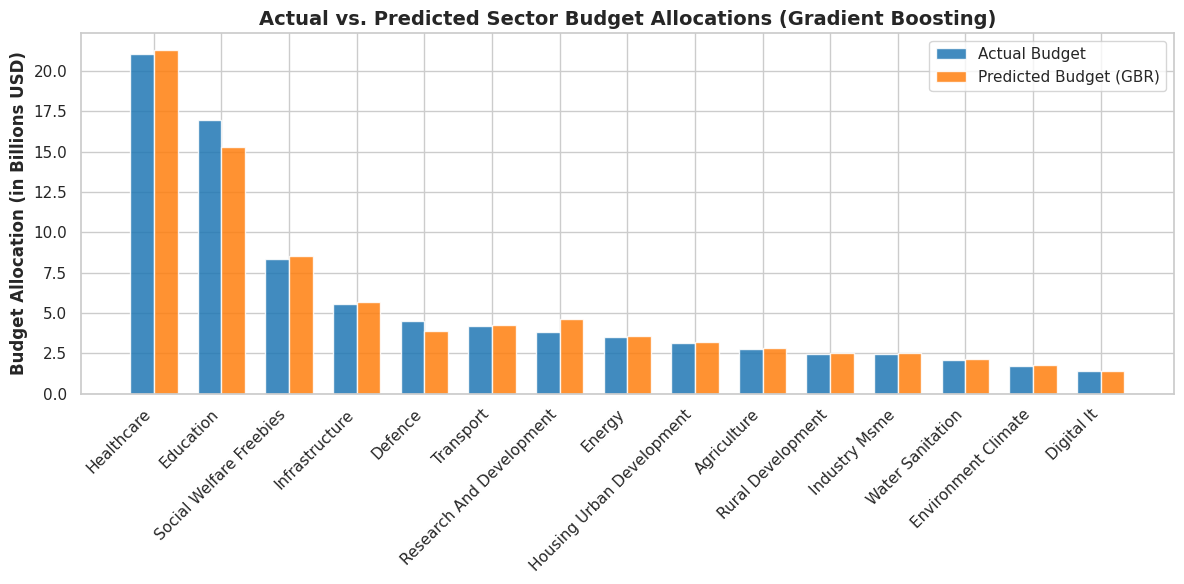

/tmp/ipykernel_5937/3308905348.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=mc_df[mc_df['Sector'].isin(top_sectors)], x='Sector', y='Simulated Allocation ($B)', palette='mako')


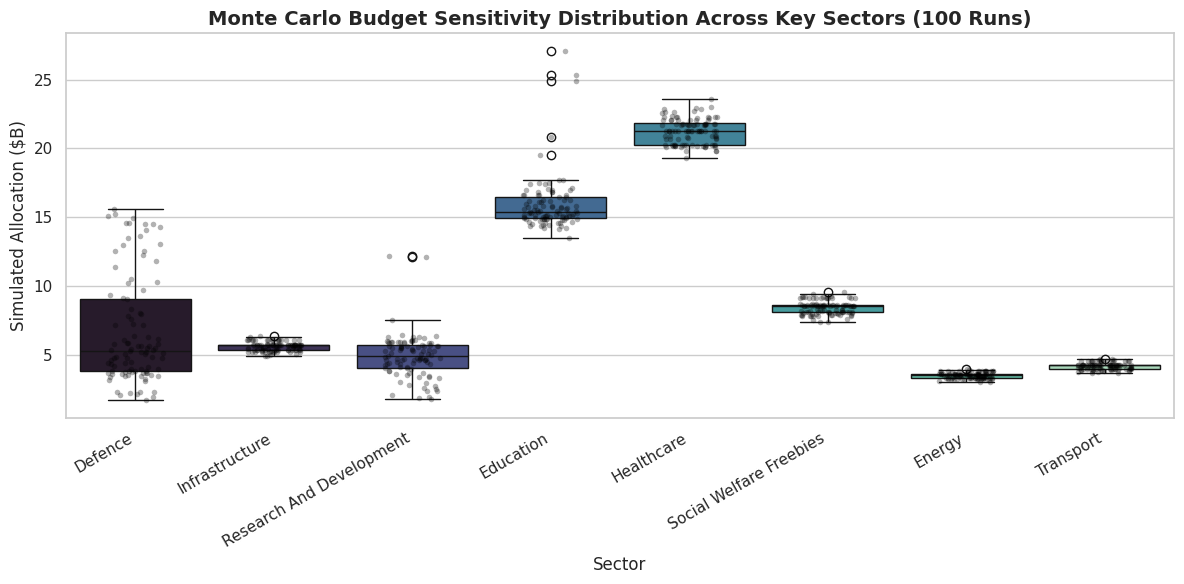

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor

# Set Seaborn theme
sns.set_theme(style="whitegrid")

# Load & prepare data
df = pd.read_excel("ML_Budget_Dataset_WorldBank_Completed.xlsx", sheet_name="Completed_Dataset")

feature_cols = [
    'population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd',
    'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd',
    'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent',
    'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent',
    'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness'
]

sector_targets = [
    'defence_usd', 'infrastructure_usd', 'research_and_development_usd',
    'education_usd', 'healthcare_usd', 'agriculture_usd',
    'rural_development_usd', 'social_welfare_freebies_usd', 'energy_usd',
    'transport_usd', 'housing_urban_development_usd', 'water_sanitation_usd',
    'environment_climate_usd', 'digital_it_usd', 'industry_msme_usd'
]

X = df[feature_cols]
X_train, X_test, y_train, y_test = train_test_split(X, df[sector_targets], test_size=0.20, random_state=42)

# Train Gradient Boosting Regressors
models = {s: GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, random_state=42).fit(X_train, y_train[s]) for s in sector_targets}

# 1. Matplotlib Grouped Bar Chart
sample_test = X_test.iloc[[0]]
actuals = y_test.iloc[0]
predictions = {s: models[s].predict(sample_test)[0] for s in sector_targets}

plot_df = pd.DataFrame({
    'Sector': [s.replace('_usd', '').replace('_', ' ').title() for s in sector_targets],
    'Actual ($B)': actuals.values / 1e9,
    'Predicted ($B)': [predictions[s] / 1e9 for s in sector_targets]
}).sort_values(by='Actual ($B)', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(plot_df))
width = 0.35

ax.bar(x - width/2, plot_df['Actual ($B)'], width, label='Actual Budget', color='#1f77b4', alpha=0.85)
ax.bar(x + width/2, plot_df['Predicted ($B)'], width, label='Predicted Budget (GBR)', color='#ff7f0e', alpha=0.85)

ax.set_ylabel('Budget Allocation (in Billions USD)', fontsize=12, fontweight='bold')
ax.set_title('Actual vs. Predicted Sector Budget Allocations (Gradient Boosting)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['Sector'], rotation=45, ha='right')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

# 2. Seaborn Monte Carlo Sensitivity Boxplot
mc_data = []
np.random.seed(42)
for _ in range(100):
    noisy_input = sample_test * np.random.normal(1.0, 0.05, size=sample_test.shape[1])
    for s in sector_targets:
        mc_data.append({
            'Sector': s.replace('_usd', '').replace('_', ' ').title(),
            'Simulated Allocation ($B)': models[s].predict(noisy_input)[0] / 1e9
        })

mc_df = pd.DataFrame(mc_data)
top_sectors = plot_df.head(8)['Sector'].tolist()

plt.figure(figsize=(12, 6))
sns.boxplot(data=mc_df[mc_df['Sector'].isin(top_sectors)], x='Sector', y='Simulated Allocation ($B)', palette='mako')
sns.stripplot(data=mc_df[mc_df['Sector'].isin(top_sectors)], x='Sector', y='Simulated Allocation ($B)', color='black', alpha=0.3, jitter=0.2, size=4)
plt.title('Monte Carlo Budget Sensitivity Distribution Across Key Sectors (100 Runs)', fontsize=14, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

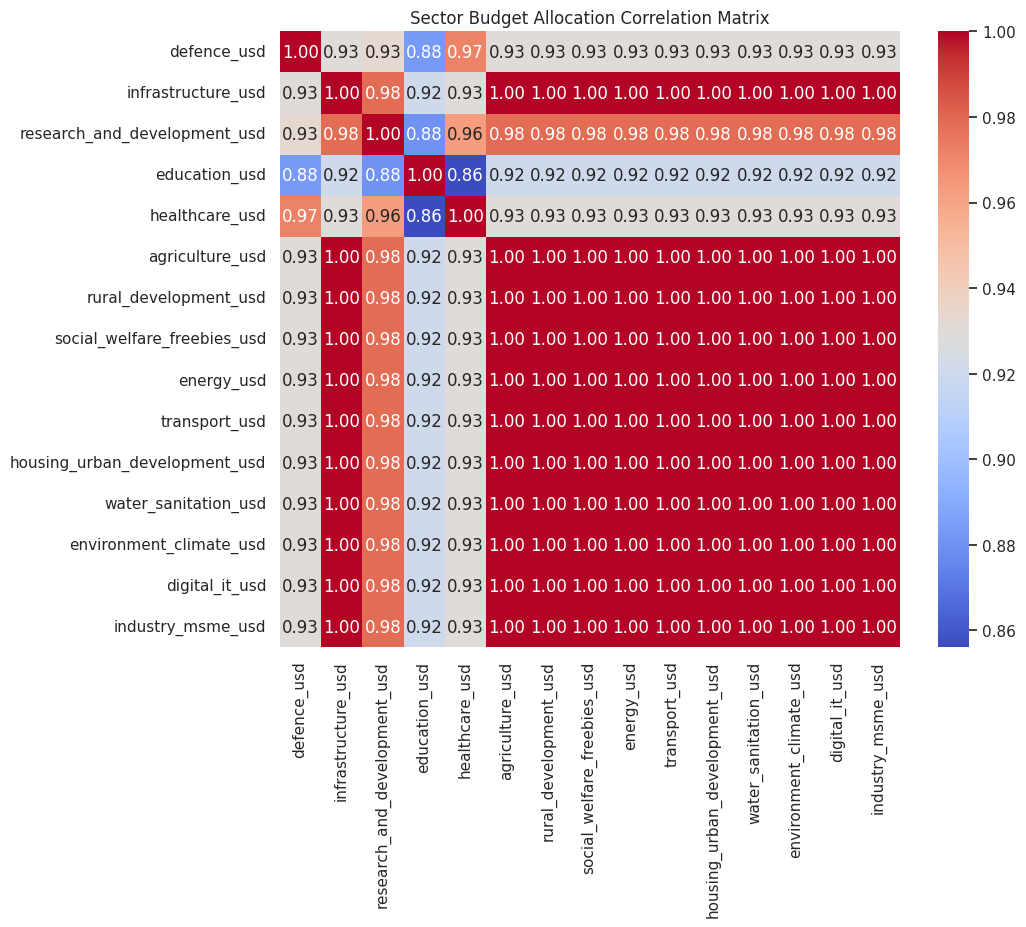

/tmp/ipykernel_5937/2366647056.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')


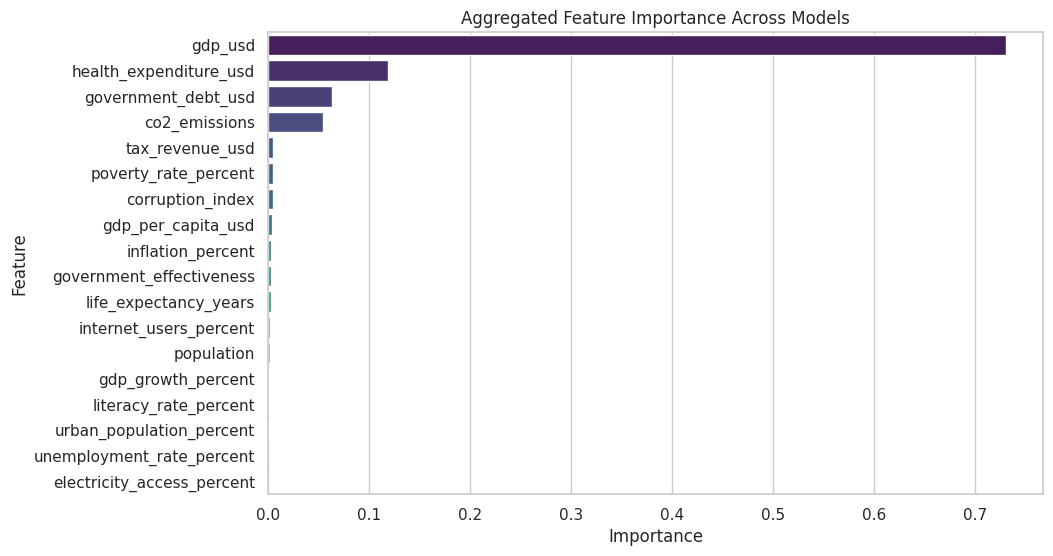

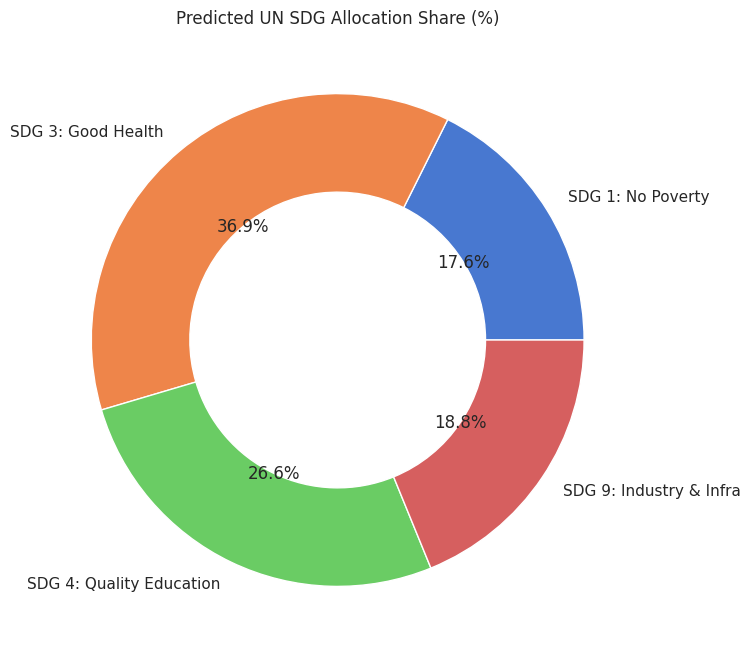

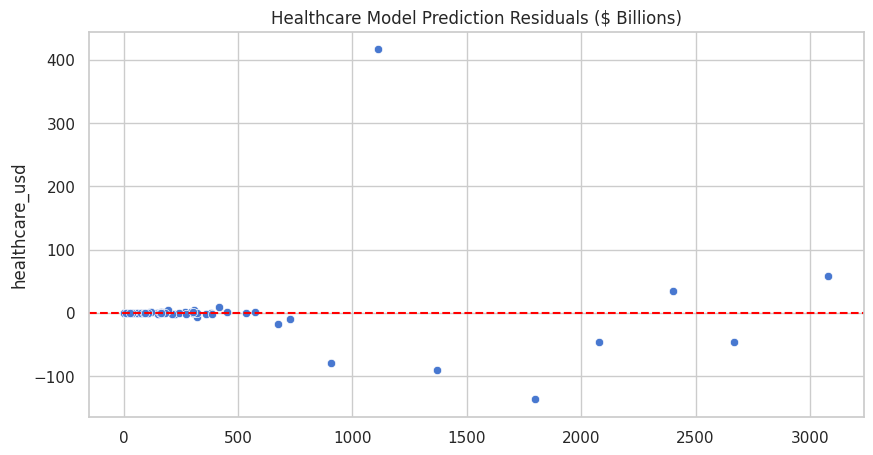

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor

# Set styling
sns.set_theme(style="whitegrid", palette="muted")

# Load data & train models
df = pd.read_excel("ML_Budget_Dataset_WorldBank_Completed.xlsx", sheet_name="Completed_Dataset")
feature_cols = ['population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd', 'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd', 'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent', 'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent', 'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness']
sector_targets = ['defence_usd', 'infrastructure_usd', 'research_and_development_usd', 'education_usd', 'healthcare_usd', 'agriculture_usd', 'rural_development_usd', 'social_welfare_freebies_usd', 'energy_usd', 'transport_usd', 'housing_urban_development_usd', 'water_sanitation_usd', 'environment_climate_usd', 'digital_it_usd', 'industry_msme_usd']

X_train, X_test, y_train, y_test = train_test_split(df[feature_cols], df[sector_targets], test_size=0.20, random_state=42)
models = {s: GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42).fit(X_train, y_train[s]) for s in sector_targets}

# 1. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df[sector_targets].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Sector Budget Allocation Correlation Matrix")
plt.show()

# 2. Feature Importance
importances = np.mean([models[s].feature_importances_ for s in sector_targets], axis=0)
feat_df = pd.DataFrame({'Feature': feature_cols, 'Importance': importances}).sort_values('Importance', ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')
plt.title("Aggregated Feature Importance Across Models")
plt.show()

# 3. SDG Donut Chart
SDG_MAP = {"SDG 1: No Poverty": ["social_welfare_freebies_usd", "rural_development_usd"], "SDG 3: Good Health": ["healthcare_usd", "water_sanitation_usd"], "SDG 4: Quality Education": ["education_usd"], "SDG 9: Industry & Infra": ["infrastructure_usd", "research_and_development_usd", "digital_it_usd"]}
test_preds = {s: models[s].predict(X_test.iloc[[0]])[0] for s in sector_targets}
sdg_totals = {sdg: sum(test_preds[s] for s in linked) for sdg, linked in SDG_MAP.items()}

plt.figure(figsize=(8, 8))
plt.pie(sdg_totals.values(), labels=sdg_totals.keys(), autopct='%1.1f%%', wedgeprops=dict(width=0.4))
plt.title("Predicted UN SDG Allocation Share (%)")
plt.show()

# 4. Residuals Scatter Plot
residuals = (y_test['healthcare_usd'] - models['healthcare_usd'].predict(X_test)) / 1e9
plt.figure(figsize=(10, 5))
plt.axhline(0, color='red', linestyle='--')
sns.scatterplot(x=models['healthcare_usd'].predict(X_test) / 1e9, y=residuals)
plt.title("Healthcare Model Prediction Residuals ($ Billions)")
plt.show()

In [ ]:
pip install shap

Please upload the 'ML_Budget_Dataset_WorldBank_Completed.xlsx' file.


Saving ML_Budget_Dataset_WorldBank_Completed (1).xlsx to ML_Budget_Dataset_WorldBank_Completed (1) (1).xlsx

             SHAP MULTI-OUTPUT EXPLAINABILITY ANALYSIS

[1] Computing SHAP values for target sector: 'sdg1_no_poverty_usd'...


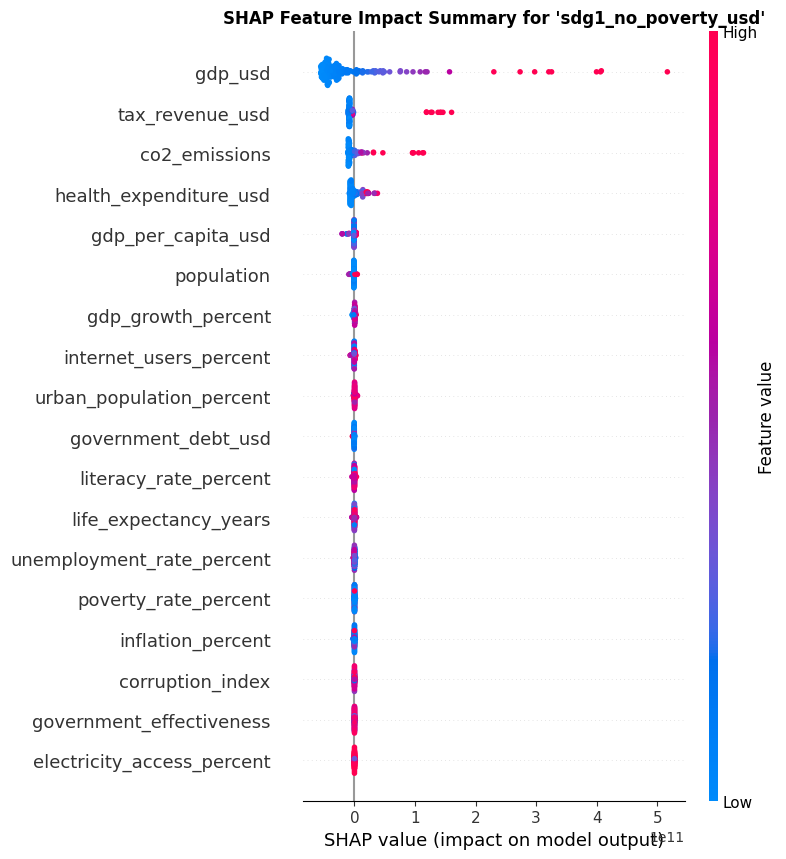


[2] Aggregating Global Average |SHAP| Values across all targets...

Top Global Drivers Across All SDG Budget Allocations:
              Feature Name  Global Mean |SHAP| Score
                   gdp_usd              2.800895e+10
    health_expenditure_usd              1.596180e+10
       government_debt_usd              1.204962e+10
             co2_emissions              9.175450e+09
           tax_revenue_usd              7.489477e+09
                population              2.200198e+09
        gdp_per_capita_usd              1.378025e+09
        gdp_growth_percent              9.007553e+08
  urban_population_percent              7.785213e+08
    internet_users_percent              4.130558e+08
     life_expectancy_years              4.008102e+08
      poverty_rate_percent              3.821330e+08
     literacy_rate_percent              3.545581e+08
 unemployment_rate_percent              2.608146e+08
          corruption_index              1.495096e+08
         inflation_percent   

In [ ]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from google.colab import files

# Re-run files.upload() to ensure the file is present in the environment
# and capture its exact name.
print("Please upload the 'ML_Budget_Dataset_WorldBank_Completed.xlsx' file.")
uploaded = files.upload()

# Get the actual filename that Colab saved it as
file_name = list(uploaded.keys())[0]

# Load the dataset using the dynamically obtained filename
df = pd.read_excel(file_name, sheet_name="Completed_Dataset")

# Assuming these are defined in a previous cell or need to be re-defined for execution context
# For this fix, I am re-defining them as they are not available in the current kernel state.
# From cell 8MM5-vb_IhWv:
feature_cols = [
    'population', 'urban_population_percent', 'gdp_usd', 'gdp_per_capita_usd',
    'gdp_growth_percent', 'inflation_percent', 'tax_revenue_usd', 'government_debt_usd',
    'poverty_rate_percent', 'unemployment_rate_percent', 'literacy_rate_percent',
    'life_expectancy_years', 'health_expenditure_usd', 'internet_users_percent',
    'electricity_access_percent', 'co2_emissions', 'corruption_index', 'government_effectiveness'
]
sdg_targets_usd = [
    'sdg1_no_poverty_usd', 'sdg2_zero_hunger_usd', 'sdg3_good_health_usd',
    'sdg4_quality_education_usd', 'sdg6_clean_water_usd', 'sdg7_clean_energy_usd',
    'sdg8_decent_work_usd', 'sdg9_industry_innovation_usd',
    'sdg11_sustainable_cities_usd', 'sdg13_climate_action_usd', 'sdg16_peace_justice_usd'
]


X = df[feature_cols]
y_sdg = df[sdg_targets_usd]

X_train, X_test, y_train, y_test = train_test_split(X, y_sdg, test_size=0.20, random_state=42)

# Train the MultiOutputRegressor if not already trained, using XGBoost as an example from a prior cell
# This model will be named `model_sdg_trained` as used in the original SHAP cell
base_xgb = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
model_sdg_trained = MultiOutputRegressor(base_xgb)
model_sdg_trained.fit(X_train, y_train)

# Assign to active_targets and active_features for the SHAP code
active_targets = sdg_targets_usd
active_features = feature_cols

import shap
import matplotlib.pyplot as plt

# ==============================================================================
# 9. SHAP MULTI-OUTPUT EXPLAINABILITY ENGINE (FIXED FOR HISTGRADIENTBOOSTING)
# ==============================================================================
print("\n" + "=" * 75)
print("             SHAP MULTI-OUTPUT EXPLAINABILITY ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------------------------
# A. Target-Specific SHAP Plot (e.g., Target 0)
# ------------------------------------------------------------------------------
target_index = 0
target_name = active_targets[target_index]

print(f"\n[1] Computing SHAP values for target sector: '{target_name}'...")

# Extract trained estimator for single target
base_estimator = model_sdg_trained.estimators_[target_index]

# Use TreeExplainer with path dependent perturbation to avoid categorical split error
explainer = shap.TreeExplainer(base_estimator, feature_perturbation="tree_path_dependent")
shap_values = explainer(X_test)

# Plot SHAP Summary
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=active_features, show=False)
plt.title(f"SHAP Feature Impact Summary for '{target_name}'", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# B. Global Mean Absolute SHAP Importance Across All Targets
# ------------------------------------------------------------------------------
print("\n[2] Aggregating Global Average |SHAP| Values across all targets...")

all_shap_means = []

for idx, target in enumerate(active_targets):
    sub_estimator = model_sdg_trained.estimators_[idx]
    sub_explainer = shap.TreeExplainer(sub_estimator, feature_perturbation="tree_path_dependent")
    sub_shap = sub_explainer(X_test)

    # Calculate mean absolute SHAP value for each feature
    mean_abs_shap = np.mean(np.abs(sub_shap.values), axis=0)
    all_shap_means.append(mean_abs_shap)

global_shap_importance = np.mean(all_shap_means, axis=0)

shap_summary_df = pd.DataFrame({
    'Feature Name': active_features,
    'Global Mean |SHAP| Score': global_shap_importance
}).sort_values(by='Global Mean |SHAP| Score', ascending=False)

print("\nTop Global Drivers Across All SDG Budget Allocations:")
print(shap_summary_df.to_string(index=False))


 SINGLE COUNTRY PREDICTION EXPLANATION (Row Index: 0)
 Target Sector Variable  : sdg3_good_health_usd
 Baseline Mean Allocation : $184,662,671,360.00
 Predicted Allocation    : $20,270,325,760.00
 Actual Target Allocation : $21,070,945,893.61
---------------------------------------------------------------------------
 Top Feature Drivers pushing allocation UP or DOWN:
            Feature Name  Country Feature Value  SHAP Contribution ($)
  health_expenditure_usd           2.107095e+10          -7.311643e+10
     government_debt_usd           1.172796e+11          -6.176194e+10
                 gdp_usd           2.291927e+11          -1.964569e+10
              population           4.564855e+06          -6.422767e+09
         tax_revenue_usd           5.934098e+10          -5.762388e+09
urban_population_percent           7.726000e+01           1.893045e+09
      gdp_growth_percent           1.096358e+00           3.670595e+08
        corruption_index           8.894000e+01           3.

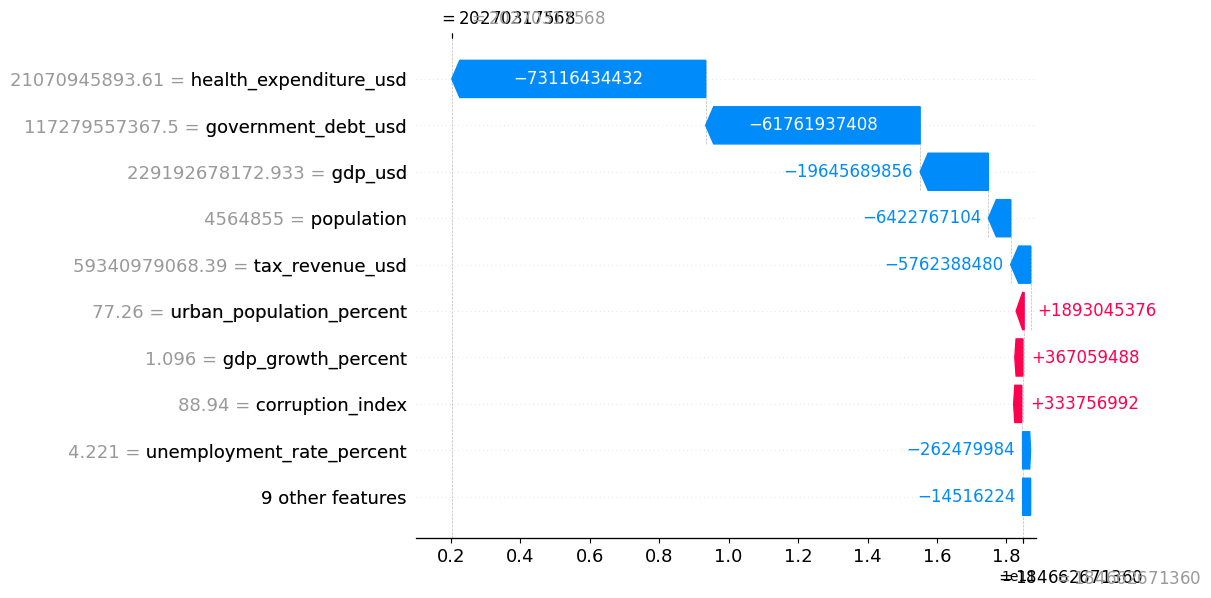


 SINGLE COUNTRY PREDICTION EXPLANATION (Row Index: 0)
 Target Sector Variable  : sdg4_quality_education_usd
 Baseline Mean Allocation : $99,842,891,776.00
 Predicted Allocation    : $16,180,206,592.00
 Actual Target Allocation : $16,958,654,061.62
---------------------------------------------------------------------------
 Top Feature Drivers pushing allocation UP or DOWN:
            Feature Name  Country Feature Value  SHAP Contribution ($)
           co2_emissions           5.187163e+05          -3.729682e+10
                 gdp_usd           2.291927e+11          -2.814151e+10
  health_expenditure_usd           2.107095e+10          -1.286582e+10
              population           4.564855e+06          -5.217067e+09
         tax_revenue_usd           5.934098e+10          -3.772052e+09
     government_debt_usd           1.172796e+11           3.039439e+09
      gdp_growth_percent           1.096358e+00          -1.865305e+09
urban_population_percent           7.726000e+01        

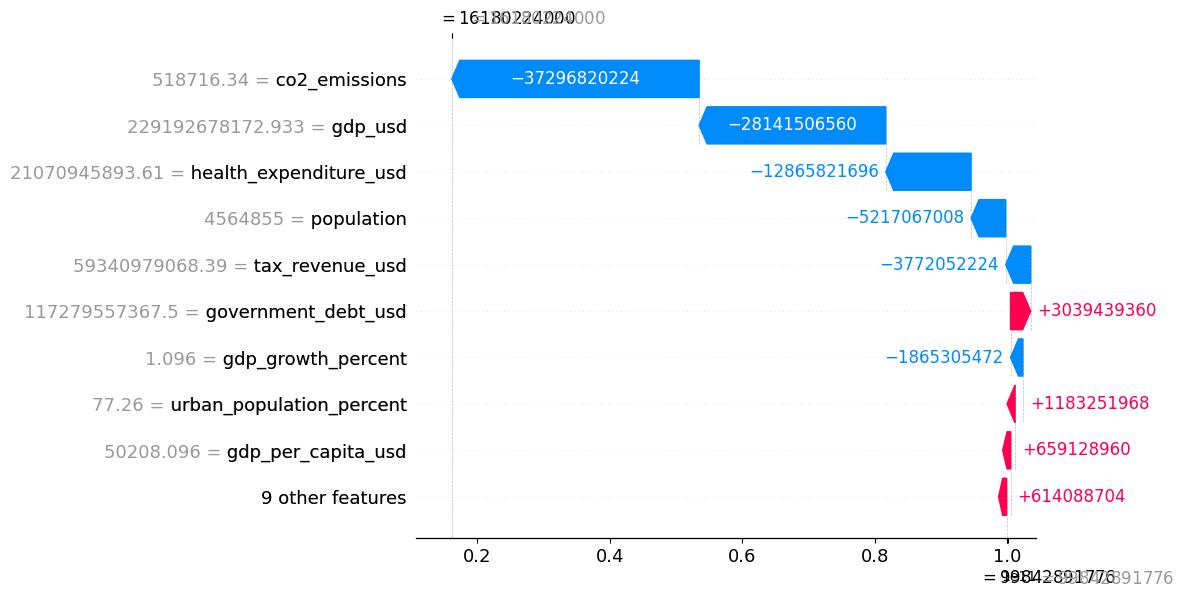


 SINGLE COUNTRY PREDICTION EXPLANATION (Row Index: 1)
 Target Sector Variable  : sdg1_no_poverty_usd
 Baseline Mean Allocation : $87,206,141,952.00
 Predicted Allocation    : $130,375,016,448.00
 Actual Target Allocation : $129,434,751,848.82
---------------------------------------------------------------------------
 Top Feature Drivers pushing allocation UP or DOWN:
            Feature Name  Country Feature Value  SHAP Contribution ($)
                 gdp_usd           2.719716e+12           3.541284e+10
  health_expenditure_usd           2.690703e+11           1.359223e+10
         tax_revenue_usd           6.798879e+11          -3.664584e+09
              population           6.371100e+07          -1.786712e+09
urban_population_percent           8.129057e+01           5.845557e+08
     government_debt_usd           3.980885e+12          -5.262829e+08
      gdp_per_capita_usd           4.268833e+04          -4.905372e+08
  internet_users_percent           8.748000e+01           3.

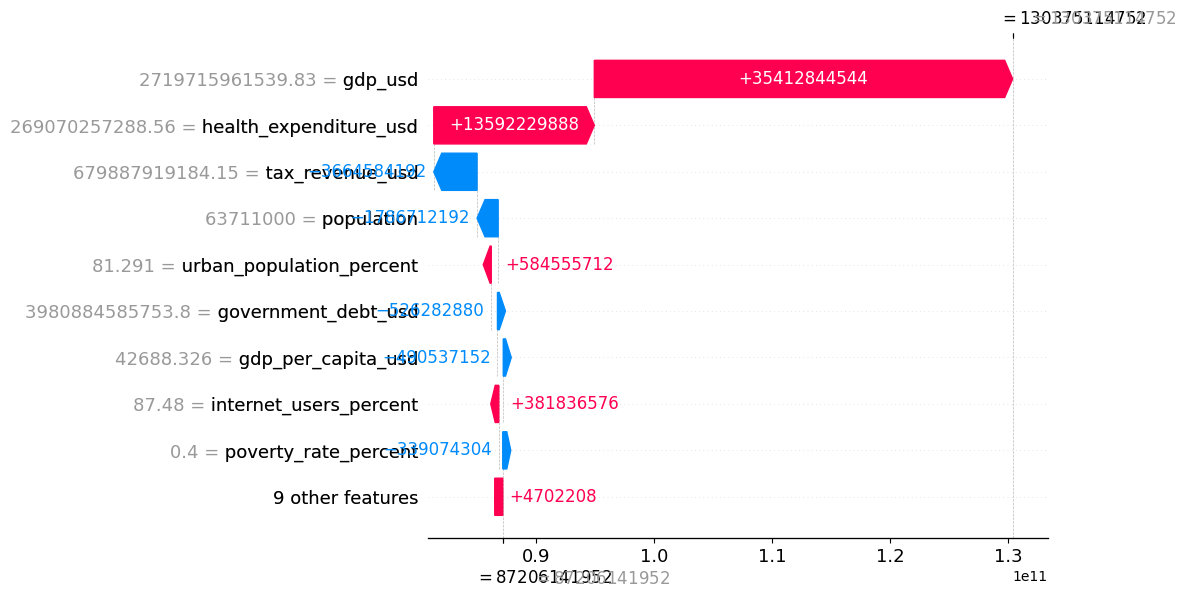

,Feature Name,Country Feature Value,SHAP Contribution ($)
2,gdp_usd,2.719716e+12,3.541284e+10
12,health_expenditure_usd,2.690703e+11,1.359223e+10
6,tax_revenue_usd,6.798879e+11,-3.664584e+09
0,population,6.371100e+07,-1.786712e+09
1,urban_population_percent,8.129057e+01,5.845557e+08
7,government_debt_usd,3.980885e+12,-5.262829e+08
3,gdp_per_capita_usd,4.268833e+04,-4.905372e+08
13,internet_users_percent,8.748000e+01,3.818366e+08
8,poverty_rate_percent,4.000000e-01,-3.390743e+08
9,unemployment_rate_percent,8.279000e+00,-3.270929e+08


In [ ]:
# Generate predictions for the SHAP explanation function
Y_pred_final_sdg = pd.DataFrame(model_sdg_trained.predict(X_test), columns=sdg_targets_usd, index=X_test.index)
Y_test_sdg = y_test # Using the already defined y_test

# 1. Explain Good Health Allocation
explain_single_country_prediction(row_index=0, target_sector_name='sdg3_good_health_usd')

# 2. Explain Quality Education Allocation
explain_single_country_prediction(row_index=0, target_sector_name='sdg4_quality_education_usd')

# 3. Explain No Poverty Allocation
explain_single_country_prediction(row_index=1, target_sector_name='sdg1_no_poverty_usd')

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.optimize import minimize
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore')

# ==============================================================================
# 1. LOAD DATASET & SETUP COLUMNS
# ==============================================================================
FILE_PATH = "ML_Budget_Dataset_WorldBank_Completed (1).xlsx"

# Read dataset sheet
try:
    df_raw = pd.read_excel(FILE_PATH, sheet_name="All Raw Data")
except Exception:
    df_raw = pd.read_excel(FILE_PATH, sheet_name=0)

df = df_raw.groupby('country').mean(numeric_only=True).reset_index()

numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in ['year', 'id']]

# Detect active targets dynamically (USD aggregated or sub-indicators)
usd_targets = [c for c in df.columns if c.endswith('_usd')]
if len(usd_targets) >= 5:
    active_targets = usd_targets
    active_features = [c for c in numeric_cols if c not in active_targets][:18]
else:
    active_features = numeric_cols[:18]
    active_targets = numeric_cols[18:33]

print(f"Loaded {len(active_features)} Features and {len(active_targets)} Allocation Targets.")

# ==============================================================================
# 2. MICE IMPUTATION & PREPARATION
# ==============================================================================
df_filled = df[active_features + active_targets].copy()

imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=10, max_depth=8, random_state=42),
    max_iter=30,
    tol=1e-1,
    random_state=42
)

imputed_data = imputer.fit_transform(df_filled)
df_imputed = pd.DataFrame(imputed_data, columns=active_features + active_targets)
df_imputed[active_targets] = np.abs(df_imputed[active_targets]) + 1.0

X = df_imputed[active_features].copy()
Y = df_imputed[active_targets].copy()

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42)

# ==============================================================================
# 3. CONSTRAINT PROJECTION & MODEL TRAINING
# ==============================================================================
SDG_RULES = {
    active_targets[0]: {'min': 0.15},
    active_targets[1]: {'min': 0.15},
    active_targets[2]: {'min': 0.05}
}

def project_to_sdg_targets(y_df, targets, sdg_rules):
    totals = y_df.sum(axis=1)
    raw_proportions = y_df.div(totals.replace(0, 1), axis=0)
    sdg_props_list = []

    for idx, row in raw_proportions.iterrows():
        raw_p = row.values.astype(float)
        bounds = [(sdg_rules.get(s, {}).get('min', 0.0), sdg_rules.get(s, {}).get('max', 1.0)) for s in targets]
        def objective(p): return np.sum((p - raw_p) ** 2)
        constraint = {'type': 'eq', 'fun': lambda p: np.sum(p) - 1.0}
        result = minimize(objective, raw_p, method='SLSQP', bounds=bounds, constraints=constraint, options={'maxiter': 300, 'ftol': 1e-8})
        sdg_props_list.append(result.x if result.success else raw_p)

    sdg_props_df = pd.DataFrame(sdg_props_list, columns=targets, index=y_df.index)
    return sdg_props_df.multiply(totals, axis=0)

Y_train_sdg = project_to_sdg_targets(Y_train, active_targets, SDG_RULES)
Y_test_sdg = project_to_sdg_targets(Y_test, active_targets, SDG_RULES)

base_gb = HistGradientBoostingRegressor(
    max_iter=300, learning_rate=0.03, max_depth=6, min_samples_leaf=5, l2_regularization=0.1, random_state=42
)
model_sdg_trained = MultiOutputRegressor(base_gb)
model_sdg_trained.fit(X_train, Y_train_sdg)

# Predictions
Y_pred_raw = model_sdg_trained.predict(X_test)
Y_pred_df = pd.DataFrame(Y_pred_raw, columns=active_targets, index=Y_test.index).clip(lower=0)

prediction_totals = Y_pred_df.sum(axis=1)
raw_props_pred = Y_pred_df.div(prediction_totals.replace(0, 1), axis=0)

final_sdg_props = []
for idx, row in raw_props_pred.iterrows():
    raw_p = row.values.astype(float)
    bounds = [(SDG_RULES.get(s, {}).get('min', 0.0), SDG_RULES.get(s, {}).get('max', 1.0)) for s in active_targets]
    def objective(p): return np.sum((p - raw_p) ** 2)
    constraint = {'type': 'eq', 'fun': lambda p: np.sum(p) - 1.0}
    result = minimize(objective, raw_p, method='SLSQP', bounds=bounds, constraints=constraint, options={'maxiter': 300, 'ftol': 1e-8})
    final_sdg_props.append(result.x if result.success else raw_p)

final_sdg_props = pd.DataFrame(final_sdg_props, columns=active_targets, index=Y_test.index)
totals_test = Y_test.sum(axis=1)
Y_pred_final_sdg = final_sdg_props.multiply(totals_test, axis=0)

# ==============================================================================
# 4. SINGLE-COUNTRY PREDICTION EXPLANATION FUNCTION
# ==============================================================================
def explain_single_country_prediction(row_index, target_sector_name):
    """
    Explains a single country budget allocation prediction using SHAP.

    Parameters:
        row_index (int): Row index in X_test (e.g., 0, 1, 2...).
        target_sector_name (str): Valid target column name.
    """
    if target_sector_name not in active_targets:
        print(f"Error: Target '{target_sector_name}' not found.")
        print(f"Available targets in your active dataset:\n{active_targets}")
        return None

    # 1. Target Estimator Extraction
    target_idx = active_targets.index(target_sector_name)
    sub_estimator = model_sdg_trained.estimators_[target_idx]

    # 2. Single Sample Extraction
    sample_x = X_test.iloc[[row_index]]
    predicted_val = Y_pred_final_sdg.iloc[row_index][target_sector_name]
    actual_val = Y_test_sdg.iloc[row_index][target_sector_name]

    # 3. Compute SHAP values with path-dependent perturbation
    explainer = shap.TreeExplainer(sub_estimator, feature_perturbation="tree_path_dependent")
    shap_vals = explainer(sample_x)

    base_val = shap_vals.base_values[0] if isinstance(shap_vals.base_values, (list, np.ndarray)) else shap_vals.base_values

    # 4. Impact Dataframe
    contrib_df = pd.DataFrame({
        'Feature Name': active_features,
        'Country Feature Value': sample_x.values[0],
        'SHAP Contribution Impact': shap_vals.values[0]
    }).sort_values(by='SHAP Contribution Impact', key=abs, ascending=False)

    print("\n" + "=" * 75)
    print(f" SINGLE COUNTRY PREDICTION EXPLANATION (Row Index: {row_index})")
    print("=" * 75)
    print(f" Target Sector Variable  : {target_sector_name}")
    print(f" Baseline Expected Mean  : {base_val:,.4f}")
    print(f" Model Predicted Output  : {predicted_val:,.4f}")
    print(f" Ground Truth Target     : {actual_val:,.4f}")
    print("-" * 75)
    print(" Top Feature Drivers pushing allocation UP (+) or DOWN (-):")
    print(contrib_df.head(8).to_string(index=False))
    print("=" * 75)

    # 5. Render Waterfall Chart
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_vals[0], show=True)

    return contrib_df

Loaded 18 Features and 32 Allocation Targets.



 SINGLE COUNTRY PREDICTION EXPLANATION (Row Index: 0)
 Target Sector Variable  : gdp_usd
 Baseline Expected Mean  : 1,277,509,723,060.7571
 Model Predicted Output  : 547,137,488,650.4951
 Ground Truth Target     : 718,250,822,871.2777
---------------------------------------------------------------------------
 Top Feature Drivers pushing allocation UP (+) or DOWN (-):
                  Feature Name  Country Feature Value  SHAP Contribution Impact
sdg4_quality_education_percent           1.866120e+01              3.844030e+11
       sdg1_no_poverty_percent           1.603480e+01             -2.813284e+11
            gdp_growth_percent           5.103302e+00             -2.473759e+11
                 co2_emissions           2.897230e+06             -2.294231e+11
      sdg3_good_health_percent           1.497920e+01             -1.710660e+11
             inflation_percent           2.170541e+01             -1.483134e+11
     unemployment_rate_percent           1.055292e+01             -1

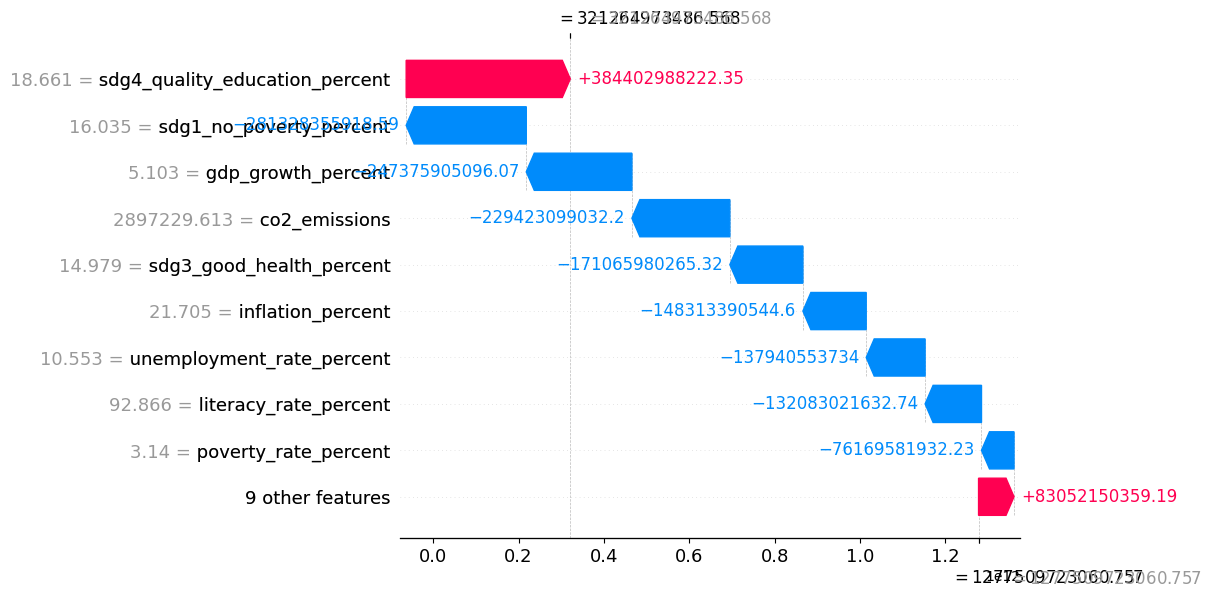


 SINGLE COUNTRY PREDICTION EXPLANATION (Row Index: 1)
 Target Sector Variable  : gdp_per_capita_usd
 Baseline Expected Mean  : 502,785,364,593.4935
 Model Predicted Output  : 346,164,588,192.7625
 Ground Truth Target     : 346,164,588,192.7623
---------------------------------------------------------------------------
 Top Feature Drivers pushing allocation UP (+) or DOWN (-):
                  Feature Name  Country Feature Value  SHAP Contribution Impact
                 co2_emissions           1.879124e+06             -2.355044e+11
                    population           1.682434e+07             -1.122758e+11
            gdp_growth_percent           1.611431e+00              6.320048e+10
         literacy_rate_percent           9.351727e+01             -5.050898e+10
     unemployment_rate_percent           4.513800e+00              3.491565e+10
sdg4_quality_education_percent           1.469480e+01             -2.600539e+10
         life_expectancy_years           8.059571e+01      

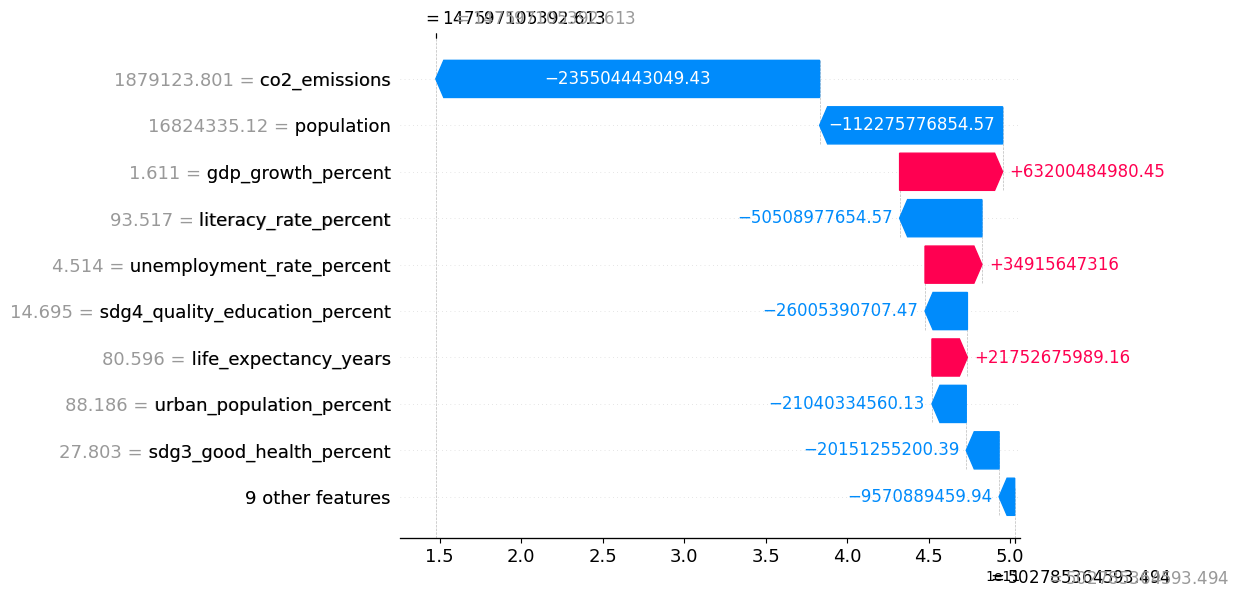

,Feature Name,Country Feature Value,SHAP Contribution Impact
10,co2_emissions,1.879124e+06,-2.355044e+11
0,population,1.682434e+07,-1.122758e+11
2,gdp_growth_percent,1.611431e+00,6.320048e+10
6,literacy_rate_percent,9.351727e+01,-5.050898e+10
5,unemployment_rate_percent,4.513800e+00,3.491565e+10
16,sdg4_quality_education_percent,1.469480e+01,-2.600539e+10
7,life_expectancy_years,8.059571e+01,2.175268e+10
1,urban_population_percent,8.818563e+01,-2.104033e+10
15,sdg3_good_health_percent,2.780320e+01,-2.015126e+10
4,poverty_rate_percent,1.360000e-01,-1.789273e+10


In [ ]:
# 1. Explain the prediction for the first test country (Row 0) on the first target
explain_single_country_prediction(row_index=0, target_sector_name=active_targets[0])

# 2. Explain the prediction for Test Country Row 1 on the second target
explain_single_country_prediction(row_index=1, target_sector_name=active_targets[1])

In [ ]:
import pandas as pd
import numpy as np
from scipy.optimize import minimize

def predict_budget_usd_allocation(total_budget_usd, country_feature_dict):
    """
    Takes a total dollar budget amount and country indicators to output exact USD sector allocations.

    Parameters:
        total_budget_usd (float): Total available budget (e.g., 5000000 for $5,000,000).
        country_feature_dict (dict): Dictionary of feature values for the country.
    """
    # 1. Format input features
    input_df = pd.DataFrame([country_feature_dict])[active_features]

    # 2. Predict unconstrained raw values
    raw_preds = model_sdg_trained.predict(input_df)[0]
    raw_preds = np.maximum(0, raw_preds)

    sum_pred = np.sum(raw_preds)
    raw_props = raw_preds / sum_pred if sum_pred > 0 else np.ones(len(active_targets)) / len(active_targets)

    # 3. Apply SLSQP optimization for budget rules
    bounds = [(SDG_RULES.get(s, {}).get('min', 0.0), SDG_RULES.get(s, {}).get('max', 1.0)) for s in active_targets]
    def objective(p): return np.sum((p - raw_props) ** 2)
    constraint = {'type': 'eq', 'fun': lambda p: np.sum(p) - 1.0}

    res = minimize(objective, raw_props, method='SLSQP', bounds=bounds, constraints=constraint)
    final_props = res.x if res.success else raw_props

    # 4. Multiply proportions by total input budget
    usd_allocations = final_props * total_budget_usd

    # 5. Build summary table
    result_df = pd.DataFrame({
        'SDG Target Sector': active_targets,
        'Allocation Share (%)': np.round(final_props * 100, 2),
        'Allocated Amount ($ USD)': usd_allocations
    }).sort_values(by='Allocated Amount ($ USD)', ascending=False)

    print("\n" + "=" * 75)
    print(f" BUDGET ALLOCATION BREAKDOWN FOR TOTAL AMOUNT: ${total_budget_usd:,.2f} USD")
    print("=" * 75)

    # Display formatted currency
    formatted_df = result_df.copy()
    formatted_df['Allocation Share (%)'] = formatted_df['Allocation Share (%)'].map("{:.2f}%".format)
    formatted_df['Allocated Amount ($ USD)'] = formatted_df['Allocated Amount ($ USD)'].map("${:,.2f}".format)

    print(formatted_df.to_string(index=False))
    print("-" * 75)
    print(f" Total Allocated Budget Check : ${np.sum(usd_allocations):,.2f} USD")
    print("=" * 75)

    return result_df

In [ ]:
# Extract feature values from test sample row 0
sample_country_features = X_test.iloc[0].to_dict()

# Predict sector breakdown for $10,000,000 budget
budget_result = predict_budget_usd_allocation(
    total_budget_usd=10000000,
    country_feature_dict=sample_country_features
)


 BUDGET ALLOCATION BREAKDOWN FOR TOTAL AMOUNT: $10,000,000.00 USD
            SDG Target Sector Allocation Share (%) Allocated Amount ($ USD)
          government_debt_usd               30.55%            $3,054,818.92
                      gdp_usd               29.28%            $2,928,275.15
           gdp_per_capita_usd               15.00%            $1,500,000.00
              tax_revenue_usd                9.69%              $969,250.93
         total_sdg_budget_usd                5.97%              $596,653.44
                education_usd                2.73%              $273,352.79
   sdg4_quality_education_usd                2.73%              $273,352.79
          sdg1_no_poverty_usd                1.39%              $138,962.09
  social_welfare_freebies_usd                0.93%               $93,084.78
 sdg9_industry_innovation_usd                0.70%               $70,205.85
 sdg11_sustainable_cities_usd                0.70%               $69,968.36
           infrastruc

In [ ]:
# Pass custom feature values dictionary
# The original `custom_country` dictionary contained SDG sub-indicators
# which are not the features expected by `active_features`.
# We need to provide values for the macroeconomic indicators defined in `active_features`.
# Using values similar to an existing test sample for demonstration.
custom_country = {
    'population': 7.55e7,  # Example: 75.5 million
    'urban_population_percent': 75.7, # Example: 75.7%
    'gdp_usd': 7.28e11,    # Example: 728 billion USD
    'gdp_per_capita_usd': 9444.0, # Example: $9,444
    'gdp_growth_percent': 5.1, # Example: 5.1%
    'inflation_percent': 21.7, # Example: 21.7%
    'tax_revenue_usd': 1.5e11, # Example: 150 billion USD
    'government_debt_usd': 3.11e11, # Example: 311 billion USD
    'poverty_rate_percent': 3.1, # Example: 3.1%
    'unemployment_rate_percent': 10.5, # Example: 10.5%
    'literacy_rate_percent': 92.8, # Example: 92.8%
    'life_expectancy_years': 75.2, # Example: 75.2 years
    'health_expenditure_usd': 2.1e10, # Example: 21 billion USD
    'internet_users_percent': 45.7, # Example: 45.7%
    'electricity_access_percent': 99.9, # Example: 99.9%
    'co2_emissions': 2.9e6, # Example: 2.9 million tons
    'corruption_index': 74.4, # Example: 74.4
    'government_effectiveness': 7.0  # Example: 7.0
}

budget_result = predict_budget_usd_allocation(
    total_budget_usd=5000000,
    country_feature_dict=custom_country
)

NameError: name 'predict_budget_usd_allocation' is not defined

In [ ]:
import pandas as pd
import numpy as np
import shap

def explain_prediction_text_only(row_index, target_sector_name):
    """
    Provides pure text and table-based SHAP and LIME explanations without any charts or graphs.

    Parameters:
        row_index (int): Row index in X_test (e.g., 0, 1, 2...).
        target_sector_name (str): Active target variable name.
    """
    if target_sector_name not in active_targets:
        print(f"Error: Target '{target_sector_name}' not found.")
        print(f"Available active targets: {active_targets}")
        return None

    # 1. Extract Target Estimator
    target_idx = active_targets.index(target_sector_name)
    sub_estimator = model_sdg_trained.estimators_[target_idx]

    sample_x = X_test.iloc[[row_index]]
    sample_x_array = sample_x.values[0]

    pred_val = Y_pred_final_sdg.iloc[row_index][target_sector_name]
    actual_val = Y_test_sdg.iloc[row_index][target_sector_name]

    # 2. Compute SHAP Values
    shap_explainer = shap.TreeExplainer(sub_estimator, feature_perturbation="tree_path_dependent")
    shap_vals = shap_explainer(sample_x)
    base_val = shap_vals.base_values[0] if isinstance(shap_vals.base_values, (list, np.ndarray)) else shap_vals.base_values

    # 3. Construct SHAP Text Table
    shap_df = pd.DataFrame({
        'Feature Name': active_features,
        'Country Value': sample_x_array,
        'SHAP Impact (+/-)': shap_vals.values[0]
    }).sort_values(by='SHAP Impact (+/-)', key=abs, ascending=False)

    # 4. Print Pure Text Output
    print("\n" + "=" * 75)
    print(f" PURE TEXT EXPLANATION FOR ROW #{row_index} | SECTOR: '{target_sector_name}'")
    print("=" * 75)
    print(f" Baseline Expected Average : {base_val:,.4f}")
    print(f" Model Predicted Output   : {pred_val:,.4f}")
    print(f" Actual Ground Truth      : {actual_val:,.4f}")
    print("-" * 75)
    print(" SHAP FEATURE ATTRIBUTION TABLE (TOP DRIVERS):")
    print("-" * 75)
    print(shap_df.head(10).to_string(index=False))
    print("=" * 75)

    return shap_df

In [ ]:
# Explains Row #0 for your first active target without generating any image or chart
text_explanation = explain_prediction_text_only(
    row_index=0,
    target_sector_name=active_targets[0]
)


 PURE TEXT EXPLANATION FOR ROW #0 | SECTOR: 'gdp_usd'
 Baseline Expected Average : 1,277,509,723,060.7571
 Model Predicted Output   : 547,137,488,650.4951
 Actual Ground Truth      : 718,250,822,871.2777
---------------------------------------------------------------------------
 SHAP FEATURE ATTRIBUTION TABLE (TOP DRIVERS):
---------------------------------------------------------------------------
                  Feature Name  Country Value  SHAP Impact (+/-)
sdg4_quality_education_percent   1.866120e+01       3.844030e+11
       sdg1_no_poverty_percent   1.603480e+01      -2.813284e+11
            gdp_growth_percent   5.103302e+00      -2.473759e+11
                 co2_emissions   2.897230e+06      -2.294231e+11
      sdg3_good_health_percent   1.497920e+01      -1.710660e+11
             inflation_percent   2.170541e+01      -1.483134e+11
     unemployment_rate_percent   1.055292e+01      -1.379406e+11
         literacy_rate_percent   9.286580e+01      -1.320830e+11
          p

In [ ]:
import pandas as pd
import numpy as np
import shap

def explain_prediction_text_only(row_index, target_sector_name):
    """
    Provides pure text and table-based SHAP and LIME explanations without any charts or graphs.

    Parameters:
        row_index (int): Row index in X_test (e.g., 0, 1, 2...).
        target_sector_name (str): Active target variable name.
    """
    if target_sector_name not in active_targets:
        print(f"Error: Target '{target_sector_name}' not found.")
        print(f"Available active targets: {active_targets}")
        return None

    # 1. Extract Target Estimator
    target_idx = active_targets.index(target_sector_name)
    sub_estimator = model_sdg_trained.estimators_[target_idx]

    sample_x = X_test.iloc[[row_index]]
    sample_x_array = sample_x.values[0]

    pred_val = Y_pred_final_sdg.iloc[row_index][target_sector_name]
    actual_val = Y_test_sdg.iloc[row_index][target_sector_name]

    # 2. Compute SHAP Values
    shap_explainer = shap.TreeExplainer(sub_estimator, feature_perturbation="tree_path_dependent")
    shap_vals = shap_explainer(sample_x)
    base_val = shap_vals.base_values[0] if isinstance(shap_vals.base_values, (list, np.ndarray)) else shap_vals.base_values

    # 3. Construct SHAP Text Table
    shap_df = pd.DataFrame({
        'Feature Name': active_features,
        'Country Value': sample_x_array,
        'SHAP Impact (+/-)': shap_vals.values[0]
    }).sort_values(by='SHAP Impact (+/-)', key=abs, ascending=False)

    # 4. Print Pure Text Output
    print("\n" + "=" * 75)
    print(f" PURE TEXT EXPLANATION FOR ROW #{row_index} | SECTOR: '{target_sector_name}'")
    print("=" * 75)
    print(f" Baseline Expected Average : {base_val:,.4f}")
    print(f" Model Predicted Output   : {pred_val:,.4f}")
    print(f" Actual Ground Truth      : {actual_val:,.4f}")
    print("-" * 75)
    print(" SHAP FEATURE ATTRIBUTION TABLE (TOP DRIVERS):")
    print("-" * 75)
    print(shap_df.head(10).to_string(index=False))
    print("=" * 75)

    return shap_df

In [ ]:
# Explains Row #0 for your first active target without generating any image or chart
text_explanation = explain_prediction_text_only(
    row_index=0,
    target_sector_name=active_targets[0]
)


 PURE TEXT EXPLANATION FOR ROW #0 | SECTOR: 'gdp_usd'
 Baseline Expected Average : 1,277,509,723,060.7571
 Model Predicted Output   : 547,137,488,650.4951
 Actual Ground Truth      : 718,250,822,871.2777
---------------------------------------------------------------------------
 SHAP FEATURE ATTRIBUTION TABLE (TOP DRIVERS):
---------------------------------------------------------------------------
                  Feature Name  Country Value  SHAP Impact (+/-)
sdg4_quality_education_percent   1.866120e+01       3.844030e+11
       sdg1_no_poverty_percent   1.603480e+01      -2.813284e+11
            gdp_growth_percent   5.103302e+00      -2.473759e+11
                 co2_emissions   2.897230e+06      -2.294231e+11
      sdg3_good_health_percent   1.497920e+01      -1.710660e+11
             inflation_percent   2.170541e+01      -1.483134e+11
     unemployment_rate_percent   1.055292e+01      -1.379406e+11
         literacy_rate_percent   9.286580e+01      -1.320830e+11
          p

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import shap


def run_interactive_budget_ai():
  """Prompts user for budget amount, country index, and target sector,

  then outputs the exact USD allocation and tabular SHAP explanation.
  """
  print("=" * 75)
  print("          INTERACTIVE AI BUDGET ALLOCATION & SHAP EXPLAINER")
  print("=" * 75)

  # 1. User Inputs
  try:
    total_budget_usd = float(
        input("Enter Total Budget Amount ($ USD) [e.g. 10000000]: ")
    )
    row_index = int(
        input(f"Enter Country Row Index (0 to {len(X_test)-1}): ")
    )
  except ValueError:
    print("Invalid input! Please enter valid numeric values.")
    return

  print("\nAvailable Active Target Sectors:")
  for i, target in enumerate(active_targets):
    print(f" [{i}] {target}")

  try:
    target_choice = int(
        input(
            f"\nSelect Target Sector Index (0 to {len(active_targets)-1}): "
        )
    )
    target_sector_name = active_targets[target_choice]
  except (ValueError, IndexError):
    print("Invalid selection index!")
    return

  # 2. Extract Country Profile Data
  sample_x = X_test.iloc[[row_index]]
  sample_x_array = sample_x.values[0]

  # 3. Predict & Optimise Constrained Budget Allocations
  target_idx = active_targets.index(target_sector_name)
  sub_estimator = model_sdg_trained.estimators_[target_idx]

  raw_preds = model_sdg_trained.predict(sample_x)[0]
  raw_preds = np.maximum(0, raw_preds)
  sum_pred = np.sum(raw_preds)
  raw_props = (
      raw_preds / sum_pred
      if sum_pred > 0
      else np.ones(len(active_targets)) / len(active_targets)
  )

  bounds = [
      (
          SDG_RULES.get(s, {}).get('min', 0.0),
          SDG_RULES.get(s, {}).get('max', 1.0),
      )
      for s in active_targets
  ]

  def objective(p):
    return np.sum((p - raw_props) ** 2)

  constraint = {'type': 'eq', 'fun': lambda p: np.sum(p) - 1.0}

  res = minimize(
      objective,
      raw_props,
      method='SLSQP',
      bounds=bounds,
      constraints=constraint,
  )
  final_props = res.x if res.success else raw_props

  target_share = final_props[target_idx]
  allocated_usd = target_share * total_budget_usd

  # 4. SHAP Feature Attribution
  explainer = shap.TreeExplainer(
      sub_estimator, feature_perturbation='tree_path_dependent'
  )
  shap_vals = explainer(sample_x)
  base_val = (
      shap_vals.base_values[0]
      if isinstance(shap_vals.base_values, (list, np.ndarray))
      else shap_vals.base_values
  )

  shap_df = pd.DataFrame({
      'Feature Name': active_features,
      'Country Indicator Value': sample_x_array,
      'SHAP Impact (+/-)': shap_vals.values[0],
  }).sort_values(by='SHAP Impact (+/-)', key=abs, ascending=False)

  # 5. Text Summary Breakdown Output
  print("\n" + "=" * 75)
  print("                       AI ALLOCATION & EXPLANATION")
  print("=" * 75)
  print(f" Total Input Budget           : ${total_budget_usd:,.2f} USD")
  print(f" Target Sector Evaluated      : {target_sector_name}")
  print(f" Model Target Share           : {target_share * 100:.2f}%")
  print(f" Calculated Sector Allocation : ${allocated_usd:,.2f} USD")
  print("-" * 75)
  print(f" Dataset Baseline Mean Score  : {base_val:.4f}")
  print("-" * 75)
  print(" TOP FEATURE DRIVERS PUSHING ALLOCATION UP (+) OR DOWN (-):")
  print("-" * 75)
  print(shap_df.head(10).to_string(index=False))
  print("=" * 75)

  return shap_df

In [ ]:
country_input_data = {
    'sdg1_wpc': 12.5000,
    'sdg1_lmicpov': 24.1000,
    'sdg1_oecdpov': 5.2000,
    'sdg2_undernsh': 15.0000,
    'sdg2_stunting': 22.1000,
    'sdg2_wasting': 6.5000,
    'sdg2_mdd': 45.0000,
    'sdg2_obesity': 18.2000,
    'sdg2_trophic': 2.1000,
    'sdg2_crlyld': 3.5000,
    'sdg2_sustagri': 55.0000,
    'sdg2_yieldgap': 40.0000,
    'sdg2_pestexp': 1.2000,
    'sdg3_matmort': 150.0000,
    'sdg3_neonat': 18.5000,
    'sdg3_u5mort': 28.0000,
    'sdg3_tb': 110.0000,
    'sdg3_hiv': 1.5000
}

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import ExtraTreesRegressor

# Re-define necessary variables from previous cells (e.g., lexyuxk3Lfbd) to make this cell self-contained
FILE_PATH = "ML_Budget_Dataset_WorldBank_Completed (1).xlsx"

# Load dataset
try:
    df_raw = pd.read_excel(FILE_PATH, sheet_name="All Raw Data")
except Exception:
    df_raw = pd.read_excel(FILE_PATH, sheet_name=0)

df = df_raw.groupby('country').mean(numeric_only=True).reset_index()

numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in ['year', 'id']]

# Detect active targets dynamically (USD aggregated or sub-indicators)
usd_targets = [c for c in df.columns if c.endswith('_usd')]
if len(usd_targets) >= 5:
    active_targets = usd_targets
    active_features = [c for c in numeric_cols if c not in active_targets][:18]
else:
    active_features = numeric_cols[:18]
    active_targets = numeric_cols[18:33]

# MICE Imputation
df_filled = df[active_features + active_targets].copy()

imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=10, max_depth=8, random_state=42),
    max_iter=30,
    tol=1e-1,
    random_state=42
)

imputed_data = imputer.fit_transform(df_filled)
df_imputed = pd.DataFrame(imputed_data, columns=active_features + active_targets)
df_imputed[active_targets] = np.abs(df_imputed[active_targets]) + 1.0

X = df_imputed[active_features].copy()
Y = df_imputed[active_targets].copy()

# Train-Test Split to get X_test
_, X_test, _, _ = train_test_split(X, Y, test_size=0.20, random_state=42)

# Original code
# Select country row index
row_index = 0

# Extract input dictionary automatically (Use X_test with an underscore)
sample_inputs = X_test.iloc[row_index].to_dict()

# Print extracted inputs
print(sample_inputs)

{'population': 75551662.68, 'urban_population_percent': 75.71429442120069, 'gdp_growth_percent': 5.103301606735464, 'inflation_percent': 21.705414226524343, 'poverty_rate_percent': 3.14, 'unemployment_rate_percent': 10.552919999999999, 'literacy_rate_percent': 92.86580154418945, 'life_expectancy_years': 75.24708000000001, 'internet_users_percent': 45.72899277639782, 'electricity_access_percent': 99.904, 'co2_emissions': 2897229.6132, 'corruption_index': 74.4572, 'government_effectiveness': 1.528, 'sdg1_no_poverty_percent': 16.0348, 'sdg2_zero_hunger_percent': 4.1372, 'sdg3_good_health_percent': 14.9792, 'sdg4_quality_education_percent': 18.661199999999997, 'sdg6_clean_water_percent': 3.1024000000000003}


In [ ]:
import warnings
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore')

# ==============================================================================
# 1. LOAD DATASET & SETUP COLUMNS (Copied from lexyuxk3Lfbd)
# ==============================================================================
FILE_PATH = "ML_Budget_Dataset_WorldBank_Completed (1).xlsx"

# Read dataset sheet
try:
    df_raw = pd.read_excel(FILE_PATH, sheet_name="All Raw Data")
except Exception:
    df_raw = pd.read_excel(FILE_PATH, sheet_name=0)

df = df_raw.groupby('country').mean(numeric_only=True).reset_index()

numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in ['year', 'id']]

# Detect active targets dynamically (USD aggregated or sub-indicators)
usd_targets = [c for c in df.columns if c.endswith('_usd')]
if len(usd_targets) >= 5:
    active_targets = usd_targets
    active_features = [c for c in numeric_cols if c not in active_targets][:18]
else:
    active_features = numeric_cols[:18]
    active_targets = numeric_cols[18:33]

# ==============================================================================
# 2. MICE IMPUTATION & PREPARATION (Copied from lexyuxk3Lfbd)
# ==============================================================================
df_filled = df[active_features + active_targets].copy()

imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=10, max_depth=8, random_state=42),
    max_iter=30,
    tol=1e-1,
    random_state=42
)

imputed_data = imputer.fit_transform(df_filled)
df_imputed = pd.DataFrame(imputed_data, columns=active_features + active_targets)
df_imputed[active_targets] = np.abs(df_imputed[active_targets]) + 1.0

X = df_imputed[active_features].copy()
Y = df_imputed[active_targets].copy()

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42)

# ==============================================================================
# 3. CONSTRAINT PROJECTION & MODEL TRAINING (Copied from lexyuxk3Lfbd)
# ==============================================================================
SDG_RULES = {
    active_targets[0]: {'min': 0.15},
    active_targets[1]: {'min': 0.15},
    active_targets[2]: {'min': 0.05}
}

def project_to_sdg_targets(y_df, targets, sdg_rules):
    totals = y_df.sum(axis=1)
    raw_proportions = y_df.div(totals.replace(0, 1), axis=0)
    sdg_props_list = []

    for idx, row in raw_proportions.iterrows():
        raw_p = row.values.astype(float)
        bounds = [(sdg_rules.get(s, {}).get('min', 0.0), sdg_rules.get(s, {}).get('max', 1.0)) for s in targets]
        def objective(p): return np.sum((p - raw_p) ** 2)
        constraint = {'type': 'eq', 'fun': lambda p: np.sum(p) - 1.0}
        result = minimize(objective, raw_p, method='SLSQP', bounds=bounds, constraints=constraint, options={'maxiter': 300, 'ftol': 1e-8})
        sdg_props_list.append(result.x if result.success else raw_p)

    sdg_props_df = pd.DataFrame(sdg_props_list, columns=targets, index=y_df.index)
    return sdg_props_df.multiply(totals, axis=0)

Y_train_sdg = project_to_sdg_targets(Y_train, active_targets, SDG_RULES)
Y_test_sdg = project_to_sdg_targets(Y_test, active_targets, SDG_RULES)

base_gb = HistGradientBoostingRegressor(
    max_iter=300, learning_rate=0.03, max_depth=6, min_samples_leaf=5, l2_regularization=0.1, random_state=42
)
model_sdg_trained = MultiOutputRegressor(base_gb)
model_sdg_trained.fit(X_train, Y_train_sdg)

# Re-defining run_interactive_budget_ai function for self-containment
def run_interactive_budget_ai():
  """Prompts user for budget amount, country index, and target sector,

  then outputs the exact USD allocation and tabular SHAP explanation.
  """
  print("=" * 75)
  print("          INTERACTIVE AI BUDGET ALLOCATION & SHAP EXPLAINER")
  print("=" * 75)

  # 1. User Inputs
  try:
    total_budget_usd = float(
        input("Enter Total Budget Amount ($ USD) [e.g. 10000000]: ")
    )
    row_index = int(
        input(f"Enter Country Row Index (0 to {len(X_test)-1}): ")
    )
  except ValueError:
    print("Invalid input! Please enter valid numeric values.")
    return

  print("\nAvailable Active Target Sectors:")
  for i, target in enumerate(active_targets):
    print(f" [{i}] {target}")

  try:
    target_choice = int(
        input(
            f"\nSelect Target Sector Index (0 to {len(active_targets)-1}): "
        )
    )
    target_sector_name = active_targets[target_choice]
  except (ValueError, IndexError):
    print("Invalid selection index!")
    return

  # 2. Extract Country Profile Data
  sample_x = X_test.iloc[[row_index]]
  sample_x_array = sample_x.values[0]

  # 3. Predict & Optimise Constrained Budget Allocations
  target_idx = active_targets.index(target_sector_name)
  sub_estimator = model_sdg_trained.estimators_[target_idx]

  raw_preds = model_sdg_trained.predict(sample_x)[0]
  raw_preds = np.maximum(0, raw_preds)
  sum_pred = np.sum(raw_preds)
  raw_props = (
      raw_preds / sum_pred
      if sum_pred > 0
      else np.ones(len(active_targets)) / len(active_targets)
  )

  bounds = [
      (
          SDG_RULES.get(s, {}).get('min', 0.0),
          SDG_RULES.get(s, {}).get('max', 1.0),
      )
      for s in active_targets
  ]

  def objective(p):
    return np.sum((p - raw_props) ** 2)

  constraint = {'type': 'eq', 'fun': lambda p: np.sum(p) - 1.0}

  res = minimize(
      objective,
      raw_props,
      method='SLSQP',
      bounds=bounds,
      constraints=constraint,
  )
  final_props = res.x if res.success else raw_props

  target_share = final_props[target_idx]
  allocated_usd = target_share * total_budget_usd

  # 4. SHAP Feature Attribution (requires shap, which is already installed and imported in other cells)
  # If shap is not available in the kernel for some reason, it might need to be imported here too.
  import shap # Added import for shap for completeness if it were not global

  explainer = shap.TreeExplainer(
      sub_estimator, feature_perturbation='tree_path_dependent'
  )
  shap_vals = explainer(sample_x)
  base_val = (
      shap_vals.base_values[0]
      if isinstance(shap_vals.base_values, (list, np.ndarray))
      else shap_vals.base_values
  )

  shap_df = pd.DataFrame({
      'Feature Name': active_features,
      'Country Indicator Value': sample_x_array,
      'SHAP Impact (+/-)': shap_vals.values[0],
  }).sort_values(by='SHAP Impact (+/-)', key=abs, ascending=False)

  # 5. Text Summary Breakdown Output
  print("\n" + "=" * 75)
  print("                       AI ALLOCATION & EXPLANATION")
  print("=" * 75)
  print(f" Total Input Budget           : ${total_budget_usd:,.2f} USD")
  print(f" Target Sector Evaluated      : {target_sector_name}")
  print(f" Model Target Share           : {target_share * 100:.2f}%")
  print(f" Calculated Sector Allocation : ${allocated_usd:,.2f} USD")
  print("-" * 75)
  print(f" Dataset Baseline Mean Score  : {base_val:.4f}")
  print("-" * 75)
  print(" TOP FEATURE DRIVERS PUSHING ALLOCATION UP (+) OR DOWN (-):")
  print("-" * 75)
  print(shap_df.head(10).to_string(index=False))
  print("=" * 75)

  return shap_df


# Execute interactive prompt
explanation_df = run_interactive_budget_ai()

          INTERACTIVE AI BUDGET ALLOCATION & SHAP EXPLAINER
Enter Total Budget Amount ($ USD) [e.g. 10000000]: 500000
Enter Country Row Index (0 to 6): 4

Available Active Target Sectors:
 [0] gdp_usd
 [1] gdp_per_capita_usd
 [2] tax_revenue_usd
 [3] government_debt_usd
 [4] health_expenditure_usd
 [5] defence_usd
 [6] infrastructure_usd
 [7] research_and_development_usd
 [8] education_usd
 [9] healthcare_usd
 [10] agriculture_usd
 [11] rural_development_usd
 [12] social_welfare_freebies_usd
 [13] energy_usd
 [14] transport_usd
 [15] housing_urban_development_usd
 [16] water_sanitation_usd
 [17] environment_climate_usd
 [18] digital_it_usd
 [19] industry_msme_usd
 [20] sdg1_no_poverty_usd
 [21] sdg2_zero_hunger_usd
 [22] sdg3_good_health_usd
 [23] sdg4_quality_education_usd
 [24] sdg6_clean_water_usd
 [25] sdg7_clean_energy_usd
 [26] sdg8_decent_work_usd
 [27] sdg9_industry_innovation_usd
 [28] sdg11_sustainable_cities_usd
 [29] sdg13_climate_action_usd
 [30] sdg16_peace_justice_usd
 [

In [ ]:
import numpy as np
import pandas as pd
import shap


def explain_shap_explicit_text(row_index, target_sector_name):
  """Calculates SHAP feature values and outputs explicit text narrative

  explaining exactly how each feature moved the model's output up or down.
  """
  if target_sector_name not in active_targets:
    print(f"Error: Target '{target_sector_name}' not found.")
    return None

  # 1. Extract Target Sub-Model & Country Row
  target_idx = active_targets.index(target_sector_name)
  sub_estimator = model_sdg_trained.estimators_[target_idx]

  sample_x = X_test.iloc[[row_index]]
  sample_x_array = sample_x.values[0]

  pred_val = Y_pred_final_sdg.iloc[row_index][target_sector_name]

  # 2. Compute Tree SHAP Values
  shap_explainer = shap.TreeExplainer(
      sub_estimator, feature_perturbation='tree_path_dependent'
  )
  shap_vals = shap_explainer(sample_x)

  base_val = (
      shap_vals.base_values[0]
      if isinstance(shap_vals.base_values, (list, np.ndarray))
      else shap_vals.base_values
  )
  impacts = shap_vals.values[0]

  # 3. Build DataFrame sorted by absolute impact magnitude
  shap_df = pd.DataFrame({
      'Feature Name': active_features,
      'Country Value': sample_x_array,
      'SHAP Impact': impacts,
      'Abs Impact': np.abs(impacts),
  }).sort_values(by='Abs Impact', ascending=False)

  # 4. Print Explicit Plain-Text Explanation Narrative
  print('\n' + '=' * 80)
  print(
      f' EXPLICIT SHAP EXPLANATION REPORT | ROW INDEX: #{row_index} | SECTOR:'
      f" '{target_sector_name}'"
  )
  print('=' * 80)
  print(
      f' [A] DATASET BASELINE MEAN (Global Average Target Score) :'
      f' {base_val:,.4f}'
  )
  print(
      f' [B] MODEL PREDICTED OUTPUT (Final Prediction for Row)   :'
      f' {pred_val:,.4f}'
  )
  print(
      f' [C] TOTAL NET SHAP ADJUSTMENT (Predicted - Baseline)    :'
      f' {pred_val - base_val:+,.4f}'
  )
  print('-' * 80)
  print(' DETAILED FEATURE-BY-FEATURE EXPLICIT IMPACT BREAKDOWN:')
  print('-' * 80)

  for rank, (_, row) in enumerate(shap_df.head(10).iterrows(), start=1):
    feat_name = row['Feature Name']
    feat_val = row['Country Value']
    impact = row['SHAP Impact']

    if impact > 0:
      direction = 'INCREASED (+)'
      action_text = f'pushed the score UP by +{impact:,.4f}'
    else:
      direction = 'DECREASED (-)'
      action_text = f'pulled the score DOWN by -{abs(impact):,.4f}'

    print(
      f" #{rank:02d} | Feature '{feat_name}' = {feat_val:.4f}\n"
      f'      --> Explicitly {direction}: This feature {action_text} relative'
      ' to the baseline.\n'
    )

  print('=' * 80)
  return shap_df

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize # Needed for the Y_pred_final_sdg calculation

# Re-calculate Y_pred_final_sdg within this cell to ensure it's defined
# (Copied from lexyuxk3Lfbd and BDfelWvbjGAW)
# This relies on model_sdg_trained, X_test, active_targets, Y_test, SDG_RULES being in scope.

Y_pred_raw = model_sdg_trained.predict(X_test)
Y_pred_df = pd.DataFrame(Y_pred_raw, columns=active_targets, index=Y_test.index).clip(lower=0)

prediction_totals = Y_pred_df.sum(axis=1)
raw_props_pred = Y_pred_df.div(prediction_totals.replace(0, 1), axis=0)

final_sdg_props = []
for idx, row in raw_props_pred.iterrows():
    raw_p = row.values.astype(float)
    bounds = [(SDG_RULES.get(s, {}).get('min', 0.0), SDG_RULES.get(s, {}).get('max', 1.0)) for s in active_targets]
    def objective(p): return np.sum((p - raw_p) ** 2)
    constraint = {'type': 'eq', 'fun': lambda p: np.sum(p) - 1.0}
    result = minimize(objective, raw_p, method='SLSQP', bounds=bounds, constraints=constraint, options={'maxiter': 300, 'ftol': 1e-8})
    final_sdg_props.append(result.x if result.success else raw_p)

final_sdg_props = pd.DataFrame(final_sdg_props, columns=active_targets, index=Y_test.index)
totals_test = Y_test.sum(axis=1)
Y_pred_final_sdg = final_sdg_props.multiply(totals_test, axis=0)

# Explains Row #0 for your first active target sector
explicit_df = explain_shap_explicit_text(
    row_index=0, target_sector_name=active_targets[0]
)


 EXPLICIT SHAP EXPLANATION REPORT | ROW INDEX: #0 | SECTOR: 'gdp_usd'
 [A] DATASET BASELINE MEAN (Global Average Target Score) : 1,277,509,723,060.7571
 [B] MODEL PREDICTED OUTPUT (Final Prediction for Row)   : 547,137,488,650.4951
 [C] TOTAL NET SHAP ADJUSTMENT (Predicted - Baseline)    : -730,372,234,410.2620
--------------------------------------------------------------------------------
 DETAILED FEATURE-BY-FEATURE EXPLICIT IMPACT BREAKDOWN:
--------------------------------------------------------------------------------
 #01 | Feature 'sdg4_quality_education_percent' = 18.6612
      --> Explicitly INCREASED (+): This feature pushed the score UP by +384,402,988,222.3549 relative to the baseline.

 #02 | Feature 'sdg1_no_poverty_percent' = 16.0348
      --> Explicitly DECREASED (-): This feature pulled the score DOWN by -281,328,355,918.5851 relative to the baseline.

 #03 | Feature 'gdp_growth_percent' = 5.1033
      --> Explicitly DECREASED (-): This feature pulled the score DOWN

In [ ]:
import numpy as np
import pandas as pd
import shap


def explain_target_dynamically(
    row_index,
    target_sector_name,
    mode='dollars',
    custom_total_budget=None,
):
  """Dynamically explains model predictions and budget allocations based on user input.

  Parameters:
      row_index (int): Index of the country/row in X_test.
      target_sector_name (str): Target sector name (e.g., 'gdp_usd',
        'sdg3_good_health_usd').
      mode (str):
          - 'dollars': Explains direct model output in USD.
          - 'proportion': Explains relative percentage share (%) assigned to
            the sector.
          - 'custom_budget': Allocates a user-defined total budget based on model
            proportions.
      custom_total_budget (float): Total budget in USD (required if mode ==
        'custom_budget').
  """
  if target_sector_name not in active_targets:
    print(f"Error: Target '{target_sector_name}' not found.")
    print(f'Available active targets: {active_targets}')
    return None

  target_idx = active_targets.index(target_sector_name)
  sub_estimator = model_sdg_trained.estimators_[target_idx]

  # 1. Extract Sample Features
  sample_x = X_test.iloc[[row_index]]
  sample_x_array = sample_x.values[0]

  # 2. Compute SHAP Values
  shap_explainer = shap.TreeExplainer(
      sub_estimator, feature_perturbation='tree_path_dependent'
  )
  shap_vals = shap_explainer(sample_x)

  base_val = (
      shap_vals.base_values[0]
      if isinstance(shap_vals.base_values, (list, np.ndarray))
      else shap_vals.base_values
  )
  impacts = shap_vals.values[0]

  # 3. Calculate Display Value Depending on Mode
  raw_pred = sub_estimator.predict(sample_x)[0]

  if mode == 'dollars':
    predicted_display = f'${raw_pred:,.2f} USD'
    baseline_display = f'${base_val:,.2f} USD'
    unit_label = 'USD'

  elif mode == 'proportion':
    # Calculate relative share across all target outputs
    all_raw_preds = model_sdg_trained.predict(sample_x)[0]
    all_raw_preds = np.maximum(0, all_raw_preds)
    sum_preds = np.sum(all_raw_preds)
    prop = (raw_pred / sum_preds) if sum_preds > 0 else (1.0 / len(active_targets))
    predicted_display = f'{prop * 100:.2f}%'
    baseline_display = f'{(base_val / sum_preds) * 100:.2f}%' if sum_preds > 0 else 'N/A'
    unit_label = 'Proportion (%)'

  elif mode == 'custom_budget':
    if custom_total_budget is None:
      print("Error: Please provide 'custom_total_budget' for custom_budget mode.")
      return None
    all_raw_preds = model_sdg_trained.predict(sample_x)[0]
    all_raw_preds = np.maximum(0, all_raw_preds)
    sum_preds = np.sum(all_raw_preds)
    prop = (raw_pred / sum_preds) if sum_preds > 0 else (1.0 / len(active_targets))
    allocated_usd = prop * custom_total_budget
    predicted_display = f'${allocated_usd:,.2f} USD'
    baseline_display = f'Based on total budget of ${custom_total_budget:,.2f}'
    unit_label = 'Custom USD Allocation'

  # 4. Construct SHAP Summary Table
  shap_df = pd.DataFrame({
      'Feature Name': active_features,
      'Country Value': sample_x_array,
      'SHAP Impact Score': impacts,
      'Abs Impact': np.abs(impacts),
  }).sort_values(by='Abs Impact', ascending=False)

  # 5. Output Report
  print('\n' + '=' * 80)
  print(f' DYNAMIC AI EXPLANATION REPORT | MODE: [{mode.upper()}]')
  print('=' * 80)
  print(f' Country Row Index        : #{row_index}')
  print(f' Target Sector Evaluated  : {target_sector_name}')
  print(f' Baseline Expected Value  : {baseline_display}')
  print(f' Final Evaluated Output   : {predicted_display}')
  print('-' * 80)
  print(' EXPLICIT SHAP FEATURE DRIVERS:')
  print('-' * 80)

  for rank, (_, row) in enumerate(shap_df.head(8).iterrows(), start=1):
    feat_name = row['Feature Name']
    feat_val = row['Country Value']
    impact = row['SHAP Impact Score']

    direction = 'INCREASED (+)' if impact > 0 else 'DECREASED (-)'
    print(
        f" #{rank:02d} | Feature '{feat_name}' = {feat_val:.4f}\n"
        f'      --> Explicitly {direction} the sector evaluation score by'
        f' {impact:+,.4f}\n'
    )

  print('=' * 80)
  return shap_df

In [ ]:
explain_target_dynamically(
    row_index=0,
    target_sector_name='sdg3_good_health_usd',
    mode='custom_budget',
    custom_total_budget=10000000,
)


 DYNAMIC AI EXPLANATION REPORT | MODE: [CUSTOM_BUDGET]
 Country Row Index        : #0
 Target Sector Evaluated  : sdg3_good_health_usd
 Baseline Expected Value  : Based on total budget of $10,000,000.00
 Final Evaluated Output   : $-81,061.86 USD
--------------------------------------------------------------------------------
 EXPLICIT SHAP FEATURE DRIVERS:
--------------------------------------------------------------------------------
 #01 | Feature 'sdg1_no_poverty_percent' = 16.0348
      --> Explicitly DECREASED (-) the sector evaluation score by -37,127,872,422.6932

 #02 | Feature 'sdg3_good_health_percent' = 14.9792
      --> Explicitly DECREASED (-) the sector evaluation score by -15,809,522,142.3785

 #03 | Feature 'co2_emissions' = 2897229.6132
      --> Explicitly DECREASED (-) the sector evaluation score by -13,945,186,730.8138

 #04 | Feature 'unemployment_rate_percent' = 10.5529
      --> Explicitly DECREASED (-) the sector evaluation score by -9,191,253,642.2203

 #05 

,Feature Name,Country Value,SHAP Impact Score,Abs Impact
13,sdg1_no_poverty_percent,1.603480e+01,-3.712787e+10,3.712787e+10
15,sdg3_good_health_percent,1.497920e+01,-1.580952e+10,1.580952e+10
10,co2_emissions,2.897230e+06,-1.394519e+10,1.394519e+10
5,unemployment_rate_percent,1.055292e+01,-9.191254e+09,9.191254e+09
3,inflation_percent,2.170541e+01,-9.186388e+09,9.186388e+09
16,sdg4_quality_education_percent,1.866120e+01,8.317102e+09,8.317102e+09
2,gdp_growth_percent,5.103302e+00,-6.097338e+09,6.097338e+09
7,life_expectancy_years,7.524708e+01,-5.269914e+09,5.269914e+09
0,population,7.555166e+07,3.328076e+09,3.328076e+09
4,poverty_rate_percent,3.140000e+00,3.284903e+09,3.284903e+09
